début de création manuellement du modèle pour tenter de simuler des participants artificiels. On a le modèle déjà décrit en matlab, mais le truc c'est que c'est un long fichier, il faudra vraiment le comprendre de A à Z. 

In [72]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
import glob
import os
import cmath 
import json
import seaborn as sns
from collections import Counter
from scipy.stats import linregress

In [73]:
data = pd.read_csv("/Users/elodiehusson/Desktop/Projet/comportement AVANT STAGE/Data/Rotations/LucasBenjamin_684432bf9acc38d54321fc04.csv", skiprows=1, index_col=3)
data

,rt,url,trial_type,time_elapsed,internal_node_id,success,responses,view_history,trial_rt,response_rts,stimulus,presented_angles,stimulus_rotations,key_press,final_angle,confidence,target,score,correct
trial_index,,,,,,,,,,,,,,,,,,,
0,72492.0,external-consent.html,external-html,72692,0.0-0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,fullscreen,78581,0.0-1.0,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,12150.0,NaN,survey-dropdown,90750,0.0-2.0,NaN,"{""0"":""18-25"",""1"":""M""}",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,17536.0,NaN,survey-text,108295,0.0-3.0,NaN,"{""Q0"":""684432bf9acc38d54321fc04""}",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,56654.0,NaN,instructions,164950,0.0-4.0,NaN,NaN,"[{""page_index"":0,""viewing_time"":12674},{""page_...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
335,NaN,NaN,lb-SeqAns-visual,3158925,0.0-224.0,NaN,NaN,NaN,2167.0,NaN,Stims/Gabor_img/Gabor_0.png,"8.4713010053,-6.9664267772,-28.9437046841,14.4...","0,45,45,0,0,45,0",NaN,228.221040,0.0,25.791335,4.0,NaN
336,NaN,NaN,lb-SeqAns-visual,3170618,0.0-225.0,NaN,NaN,NaN,2620.0,NaN,Stims/Gabor_img/Gabor_0.png,"241.6571528293,116.9351700295,98.025899629,182...","-45,45,45,0,45",NaN,233.664135,0.0,176.498556,0.0,NaN
337,NaN,NaN,lb-SeqAns-visual,3176301,0.0-226.0,NaN,NaN,NaN,2659.0,NaN,Stims/Gabor_img/Gabor_0.png,92.0353409512,45,NaN,196.410785,0.0,137.035341,0.0,NaN


## Fonctions

In [74]:
def CircularMean(a):
    if len(a)==0:
        return(np.nan)
    resulting_vector = 0
    for i in range(len(a)):
        if not  np.isnan(a[i]):
            resulting_vector+= cmath.exp(complex(0, 2*a[i]))
    return((np.angle(resulting_vector))/2)

In [75]:
def circular_error(a, b):
    return 0.5 * np.angle(np.exp(1j * 2 * (a - b)))

In [76]:
def map_rotation_to_color(val):
    if np.isclose(val, np.deg2rad(45)):
        return "green"
    elif np.isclose(val, np.deg2rad(-45)):
        return "red"
    else:
        return "grey"

## Filtering du dataframe pour 1 sujet

### dataframe en degré

In [77]:
df_filtered = data[data["stimulus_rotations"].notna()]
df_filtered = df_filtered.drop(columns=["score", "target", "trial_rt", "final_angle" , "rt", "url", "time_elapsed", "internal_node_id", "success", "responses", "view_history", "response_rts", "key_press", "confidence", "correct", "trial_type", "stimulus"])
df_filtered.reset_index(drop=True, inplace=True)
df_filtered["length of sequence"] = df_filtered["presented_angles"].apply(lambda s: len(s.split(',')) if isinstance(s, str) else 0)
df_filtered['presented_angles'] = df_filtered['presented_angles'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered["expected_angles"] = df_filtered.apply(lambda row : [x + y for x,y in zip(row["presented_angles"],row["stimulus_rotations"])], axis=1)

### dataframe en radian

In [78]:
df_radian = df_filtered.copy().drop(columns=["presented_angles", "expected_angles", "stimulus_rotations"])

df_radian['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))

df_radian['presented_angles'] = df_filtered['presented_angles'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))

df_radian['expected_angles'] = df_filtered['expected_angles'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))

df_radian["target"] = df_radian["expected_angles"].apply(CircularMean) # moyenne circulaire des angles attendus
df_filtered["target"] = df_radian["target"].apply(np.rad2deg) # convert back to degrees for the original dataframe

df_radian["mean_rotation"] = df_radian["stimulus_rotations"].apply(CircularMean)

df_radian["color_map_str"] = df_radian["stimulus_rotations"].apply(
    lambda lst: [map_rotation_to_color(v) for v in lst]
)
df_radian["mean_rotation_rounded"] = df_radian["mean_rotation"].round(4)

df_radian

,length of sequence,stimulus_rotations,presented_angles,expected_angles,target,mean_rotation,color_map_str,mean_rotation_rounded
0,7,"[0.7853981633974483, 0.0, -0.7853981633974483,...","[1.148981365499507, 2.329885149108054, 2.70502...","[1.9343795288969552, 2.329885149108054, 1.9196...",-0.974011,-0.122489,"[green, grey, red, grey, red, grey, grey]",-0.1225
1,5,"[0.0, 0.7853981633974483, 0.0, -0.785398163397...","[2.6976008517068717, 2.2843827503684624, 3.116...","[2.6976008517068717, 3.0697809137659107, 3.116...",0.055244,0.231824,"[grey, green, grey, red, green]",0.2318
2,1,[-0.7853981633974483],[2.171204662540556],[1.3858064991431076],1.385806,-0.785398,[red],-0.7854
3,1,[0.0],[2.454565798814005],[2.454565798814005],-0.687027,0.000000,[grey],0.0000
4,7,"[-0.7853981633974483, 0.0, -0.7853981633974483...","[2.8250856932357697, 1.5463560211231628, 1.801...","[2.0396875298383215, 1.5463560211231628, 1.016...",1.133615,-0.231824,"[red, grey, red, grey, green, red, green]",-0.2318
...,...,...,...,...,...,...,...,...
195,7,"[0.0, 0.7853981633974483, 0.7853981633974483, ...","[0.14785209446999062, -0.12158708436123743, -0...","[0.14785209446999062, 0.6638110790362108, 0.28...",0.440748,0.321751,"[grey, green, green, grey, grey, green, grey]",0.3218
196,5,"[-0.7853981633974483, 0.7853981633974483, 0.78...","[4.217712977866415, 2.0409037283941696, 1.7108...","[3.4323148144689672, 2.8263018917916183, 2.496...",-0.046250,0.553574,"[red, green, green, grey, green]",0.5536
197,1,[0.7853981633974483],[1.6063197277940098],[2.3917178911914583],-0.749875,0.785398,[green],0.7854
198,7,"[0.0, 0.7853981633974483, -0.7853981633974483,...","[2.859158212075561, 1.1540872860958609, 3.3071...","[2.859158212075561, 1.9394854494933091, 2.5217...",-0.931541,-0.231824,"[grey, green, red, red, green, red, grey]",-0.2318


## dataframe of every sequences (from all 104 participants)

In [79]:
filepathsW = glob.glob("/Users/elodiehusson/Desktop/Projet/comportement AVANT STAGE/Data/Weights/*.csv")
dfsW = [pd.read_csv(f, skiprows=1, index_col=3) for f in filepathsW]

presented_angles_W = []
weights = []
for df in dfsW : 
    df= df[df["stimulus_weights"].notna()]
    df = df.dropna(subset=["final_angle"])
    df["presented_angles"] = df["presented_angles"].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
    df["stimulus_weights"] = df["stimulus_weights"].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
    presented_angles_W.extend(df["presented_angles"].tolist())
    weights.extend(df["stimulus_weights"].tolist())
    

df_all_W = pd.DataFrame({"presented_angles": (presented_angles_W), "stimulus_weights": weights})
df_all_W['stimulus_weights'] = df_all_W['stimulus_weights'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))

df_all_W['presented_angles'] = df_all_W['presented_angles'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))

df_all_W["expected_angles"] = df_all_W.apply(lambda row : [x + y for x,y in zip(row["presented_angles"],row["stimulus_weights"])], axis=1)
df_all_W["target"] = df_all_W["expected_angles"].apply(CircularMean) # moyenne circulaire des angles attendus
df_all_W["length of sequence"] = df_all_W["presented_angles"].apply(len)

df_all_W

ValueError: Cannot set a DataFrame with multiple columns to the single column expected_angles

In [ ]:
filepaths = glob.glob("/Users/elodiehusson/Desktop/Projet/comportement AVANT STAGE/Data/Rotations/*.csv")
dfs = [pd.read_csv(f, skiprows=1, index_col=3) for f in filepaths]
presented_angles = []
rotations = []
for df in dfs : 
    df= df[df["stimulus_rotations"].notna()]
    df = df.dropna(subset=["final_angle"])
    df["presented_angles"] = df["presented_angles"].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
    df["stimulus_rotations"] = df["stimulus_rotations"].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
    presented_angles.extend(df["presented_angles"].tolist())
    rotations.extend(df["stimulus_rotations"].tolist())

df_all = pd.DataFrame({"presented_angles": (presented_angles), "stimulus_rotations": rotations})
df_all['stimulus_rotations'] = df_all['stimulus_rotations'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))

df_all['presented_angles'] = df_all['presented_angles'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))

df_all["expected_angles"] = df_all.apply(lambda row : [x + y for x,y in zip(row["presented_angles"],row["stimulus_rotations"])], axis=1)
df_all["target"] = df_all["expected_angles"].apply(CircularMean) # moyenne circulaire des angles attendus
df_all["mean_rotation"] = df_all["stimulus_rotations"].apply(CircularMean) 
df_all["length of sequence"] = df_all["presented_angles"].apply(len)
df_all["mean_rotation_rounded"] = df_all["mean_rotation"].round(4)

df_all

,presented_angles,stimulus_rotations,expected_angles,target,mean_rotation,length of sequence,mean_rotation_rounded
0,[2.784288701620248],[0.0],[2.784288701620248],-0.357304,0.000000,1,0.0000
1,"[2.1675486772589148, 2.856820126273457, 4.1229...","[0.7853981633974483, 0.0, -0.7853981633974483,...","[2.952946840656363, 2.856820126273457, 3.33753...",-0.131179,0.231824,5,0.2318
2,"[2.516375514962319, 3.5311328937204634, 3.5112...","[0.0, -0.7853981633974483, -0.7853981633974483]","[2.516375514962319, 2.745734730323015, 2.72587...",-0.478411,-0.553574,3,-0.5536
3,"[1.0045504426981076, 1.7057270248707435, 0.943...","[0.0, -0.7853981633974483, 0.0, -0.78539816339...","[1.0045504426981076, 0.9203288614732952, 0.943...",1.192362,-0.294001,7,-0.2940
4,[3.2366968988467373],[-0.7853981633974483],[2.451298735449289],-0.690294,-0.785398,1,-0.7854
...,...,...,...,...,...,...,...
20671,"[3.5288752094320337, 3.5258300395088256, 2.783...","[-0.7853981633974483, -0.7853981633974483, -0....","[2.7434770460345854, 2.7404318761113773, 1.998...",-0.622761,-0.785398,3,-0.7854
20672,"[2.462130689571814, 2.10867334645327, 2.632352...","[0.0, 0.7853981633974483, 0.7853981633974483, ...","[2.462130689571814, 2.8940715098507184, 3.4177...",-0.245224,0.231824,5,0.2318
20673,"[2.081077763428887, 3.791914411718458, 3.48196...","[0.7853981633974483, -0.7853981633974483, -0.7...","[2.866475926826335, 3.0065162483210095, 2.6965...",-0.284909,-0.785398,3,-0.7854
20674,[3.782518117565987],[-0.7853981633974483],[2.997119954168539],-0.144473,-0.785398,1,-0.7854


## Simulation models

### optimal and suboptimal models

In [ ]:
def optimal_model (list_presented_angles, list_perceived_colors) : 
    """This model simulates the response of a participant. This is the optimal model.
    It returns only ONE target, or angle, for a given sequence 
    """
    
    # security that the lists have the same length
    if len(list_presented_angles) != len(list_perceived_colors) : 
        print(f"the list of presented angles (length = {len(list_presented_angles)}) and the list of colors presented (length = {len(list_perceived_colors)}) don't have the same length")
        return None
    
    # color mapping : each color viewed equals to an angle
    if type(list_perceived_colors[0]) == str : # if list is the colors
        color_mapping_degrees = {"green" : np.deg2rad(45), "red" : np.deg2rad(-45), "grey" : np.deg2rad(0)}
        rotations_to_apply = [color_mapping_degrees[x] for x in list_perceived_colors] # les rotations à appliquer
    else : 
        rotations_to_apply = list_perceived_colors

    corrected_angles = np.array(list_presented_angles) + np.array(rotations_to_apply)
    
    if len(corrected_angles) == 0:
        result = np.nan
    else:
        result = corrected_angles
    resulting_vector = 0
    for i in range(len(corrected_angles)):
        if not  np.isnan(result[i]):
            resulting_vector+= cmath.exp(complex(0,2* corrected_angles[i]))
        # print(np.angle(resulting_vector)/2)
    target = np.angle(resulting_vector)/2        


    return target

In [81]:
def optimal_model_poster_RH2 (list_presented_angles, list_perceived_colors) : 
    """This model simulates the response of a participant. This is the optimal model.
    It returns only ONE target, or angle, for a given sequence 
    """
    length = len(list_presented_angles)
    posteriors = []
    surprise = []

    # print("lenght of presented angles : ", len(list_presented_angles))
    # security that the lists have the same length
    if len(list_presented_angles) != len(list_perceived_colors) : 
        print(f"the list of presented angles (length = {len(list_presented_angles)}) and the list of colors presented (length = {len(list_perceived_colors)}) don't have the same length")
        return None
    
    
    # color mapping : each color viewed equals to an angle
    if type(list_perceived_colors[0]) == str : # if list is the colors
        color_mapping_degrees = {"green" : np.deg2rad(45), "red" : np.deg2rad(-45), "grey" : np.deg2rad(0)}
        rotations_to_apply = [color_mapping_degrees[x] for x in list_perceived_colors] # les rotations à appliquer
    else : 
        rotations_to_apply = list_perceived_colors

    corrected_angles = np.array(list_presented_angles) + np.array(rotations_to_apply)
    
    if len(corrected_angles) == 0:
        result = np.nan
    else:
        result = corrected_angles
    resulting_vector = 0
    for i in range(len(corrected_angles)):
        if not  np.isnan(result[i]):
            resulting_vector+= cmath.exp(complex(0,2* corrected_angles[i]))
        post = np.angle(resulting_vector)/2%np.pi
        posteriors.append(post)
        surprise.append(np.abs(circular_error(post%np.pi,(posteriors[i-1])%np.pi)))
        # print(np.rad2deg(np.angle(resulting_vector)/2))
    target = np.angle(resulting_vector)/2        


    return target, length, posteriors, surprise, corrected_angles

def optimal_model_poster_RH01 (list_presented_angles, list_perceived_colors) : 
    """This model simulates the response of a participant. This is the optimal model.
    It returns only ONE target, or angle, for a given sequence 
    """
    length = len(list_presented_angles)
    posteriors = []
    surprise = []

    # print("lenght of presented angles : ", len(list_presented_angles))
    # security that the lists have the same length
    if len(list_presented_angles) != len(list_perceived_colors) : 
        print(f"the list of presented angles (length = {len(list_presented_angles)}) and the list of colors presented (length = {len(list_perceived_colors)}) don't have the same length")
        return None
    
    
    # color mapping : each color viewed equals to an angle
    if type(list_perceived_colors[0]) == str : # if list is the colors
        color_mapping_degrees = {"green" : np.deg2rad(0), "red" : np.deg2rad(-0), "grey" : np.deg2rad(0)}
        rotations_to_apply = [color_mapping_degrees[x] for x in list_perceived_colors] # les rotations à appliquer
    else : 
        rotations_to_apply = list_perceived_colors

    corrected_angles = np.array(list_presented_angles) + np.array(rotations_to_apply)
    
    if len(corrected_angles) == 0:
        result = np.nan
    else:
        result = corrected_angles
    resulting_vector = 0
    for i in range(len(corrected_angles)):
        if not  np.isnan(result[i]):
            resulting_vector+= cmath.exp(complex(0,2* corrected_angles[i]))
        post = np.angle(resulting_vector)/2%np.pi
        posteriors.append(post)
        surprise.append(np.abs(circular_error(post%np.pi,(posteriors[i-1])%np.pi)))
        # print(np.rad2deg(np.angle(resulting_vector)/2))
    target = np.angle(resulting_vector)/2        


    return target, length, posteriors, surprise

In [ ]:
def optimal_model_poster_WH2 (list_presented_angles, list_weights) : 

    length = len(list_presented_angles)
    posteriors = []
    surprise = []

    # print("lenght of presented angles : ", len(list_presented_angles))
    # security that the lists have the same length
    if len(list_presented_angles) != len(list_weights) : 
        print(f"the list of presented angles (length = {len(list_presented_angles)}) and the list of weights (length = {len(list_weights)}) don't have the same length")
        return None
    
    
    
    resulting_vector = 0
    for angle, weight, i  in zip(list_presented_angles, list_weights, range(len(list_presented_angles))):
        resulting_vector+= weight* cmath.exp(complex(0,2  * angle))
        post = np.angle(resulting_vector)/2%np.pi
        posteriors.append(post)
        surprise.append(np.abs(circular_error(post%np.pi,(posteriors[i-1])%np.pi)))
        
        
    target = np.angle(resulting_vector)/2       
    return target, length, posteriors, surprise  
    
    
    
    

def optimal_model_poster_WH01 (list_presented_angles, list_weights) : 

    length = len(list_presented_angles)
    posteriors = []
    surprise = []

    # print("lenght of presented angles : ", len(list_presented_angles))
    # security that the lists have the same length
    if len(list_presented_angles) != len(list_weights) : 
        print(f"the list of presented angles (length = {len(list_presented_angles)}) and the list of weights (length = {len(list_weights)}) don't have the same length")
        return None
    
    
    
    resulting_vector = 0
    for angle, weight, i in zip(list_presented_angles, list_weights, range(len(list_presented_angles))):
        resulting_vector+= cmath.exp(complex(0,2  * angle))
        post = np.angle(resulting_vector)/2%np.pi
        posteriors.append(post)
        surprise.append(np.abs(circular_error(post%np.pi,(posteriors[i-1])%np.pi)))
        
        
    target = np.angle(resulting_vector)/2       
    return target, length, posteriors, surprise  
   

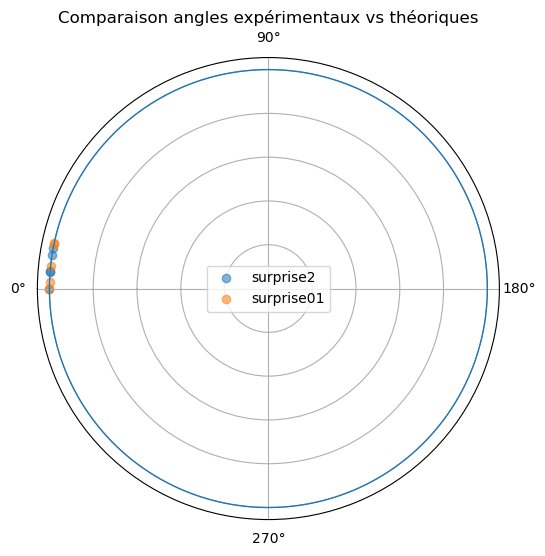

In [ ]:
# for the SUBoptimal model
num = 1
list_presented_angles = df_radian["presented_angles"].iloc[num] 
list_perceived_colors = df_radian["color_map_str"].iloc[num]

target2, length2, posteriors2, surprise2, corrected_angles = optimal_model_poster_RH2(list_presented_angles,list_perceived_colors)
target01, length01, posteriors01, surprise01 = optimal_model_poster_RH01(list_presented_angles,list_perceived_colors)

# print("posterior", posteriors)
# print("surprise", surprise)
# print("presented angles", list_presented_angles)
# print("colors", list_perceived_colors)

### plot sur cercle 

fig = plt.figure(figsize=(6,6))
ax = plt.subplot(111, polar=True)

ax.set_theta_zero_location("W")   
ax.set_theta_direction(-1)        # sens horaire

# ---- CERCLE TRIGONOMÉTRIQUE ----
theta = np.linspace(0, np.pi*2, 400)
ax.plot(theta, np.ones_like(theta), linewidth=1)  # cercle unité

# labels angulaires
ax.set_thetagrids(
    angles=[0, 90, 180, 270],
    labels=["0°", "90°", "180°", "270°"]

)

# ---- TES DONNÉES ----
# x = [20, 40, 60, 120, 100 ]
# ax.scatter(posteriors2, np.ones_like(posteriors),
#            alpha=0.55, label="Experimentaux")
ax.scatter(surprise2, np.ones_like(surprise2),
           alpha=0.55, label="surprise2")
ax.scatter(surprise01, np.ones_like(surprise01),
           alpha=0.55, label="surprise01")


# ax.scatter(list_presented_angles, np.ones_like(list_presented_angles),
#            alpha=0.55, label="presented angles")

ax.set_yticklabels([])   # enlève les labels du rayon
ax.set_title("Comparaison angles expérimentaux vs théoriques")
ax.legend()

plt.show()

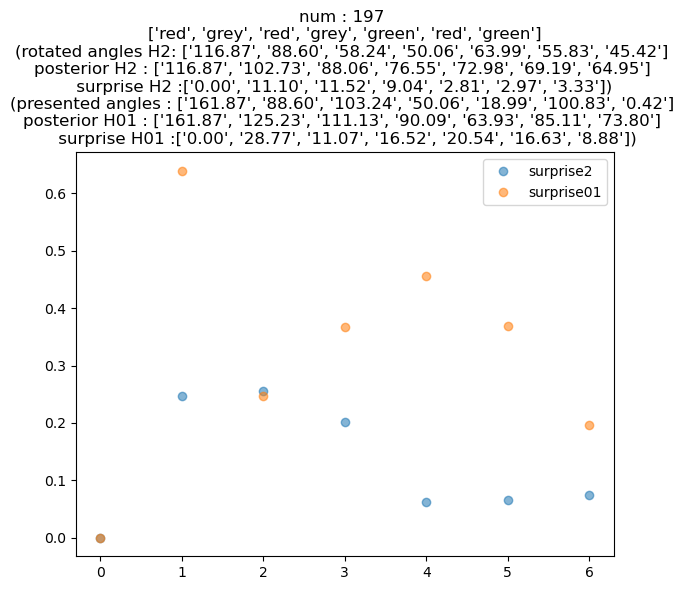

73.8009829109595


In [83]:
list_presented_angles = df_radian["presented_angles"].iloc[4] 
list_perceived_colors = df_radian["color_map_str"].iloc[4]
target2, length2, posteriors2, surprise2, corrected_angles = optimal_model_poster_RH2(list_presented_angles,list_perceived_colors)
target01, length01, posteriors01, surprise01 = optimal_model_poster_RH01(list_presented_angles,list_perceived_colors)

rounded_post2 = [f"{np.rad2deg(x):.2f}" for x in posteriors2]
rounded_surprise2 = [f"{x*45:.2f}" for x in surprise2]
rounded_post01 = [f"{np.rad2deg(x):.2f}" for x in posteriors01]
rounded_surprise01 = [f"{x*45:.2f}" for x in surprise01]
list_presented_angles = [f"{np.rad2deg(x):.2f}" for x in list_presented_angles]
corrected_angles = [f"{np.rad2deg(x):.2f}" for x in corrected_angles]

plt.figure(figsize=(6,6))
plt.plot(surprise2, 'o', alpha=0.55, label="surprise2")
plt.plot(surprise01, 'o', alpha=0.55, label="surprise01")
plt.title(f"num : {num} \n{list_perceived_colors}\n(rotated angles H2: {corrected_angles} \nposterior H2 : {rounded_post2} \n surprise H2 :{rounded_surprise2}) \n(presented angles : {list_presented_angles} \nposterior H01 : {rounded_post01} \n surprise H01 :{rounded_surprise01})")
plt.legend()
plt.tight_layout()
# ax.set_title(f"num : {num}")
plt.show()
print(np.rad2deg(target01))

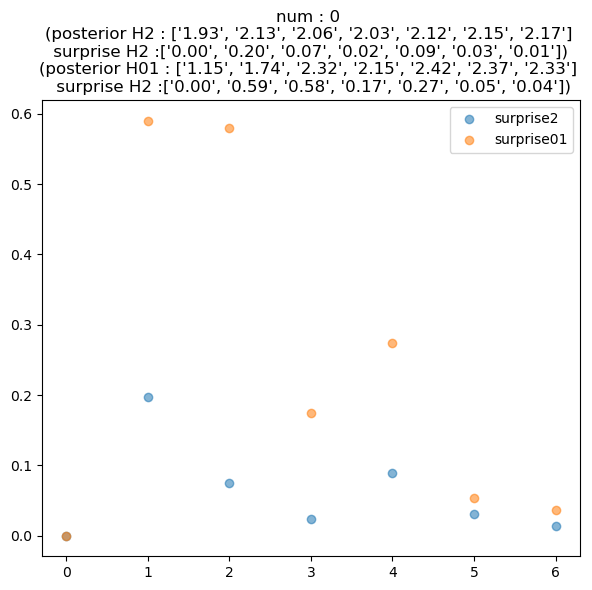

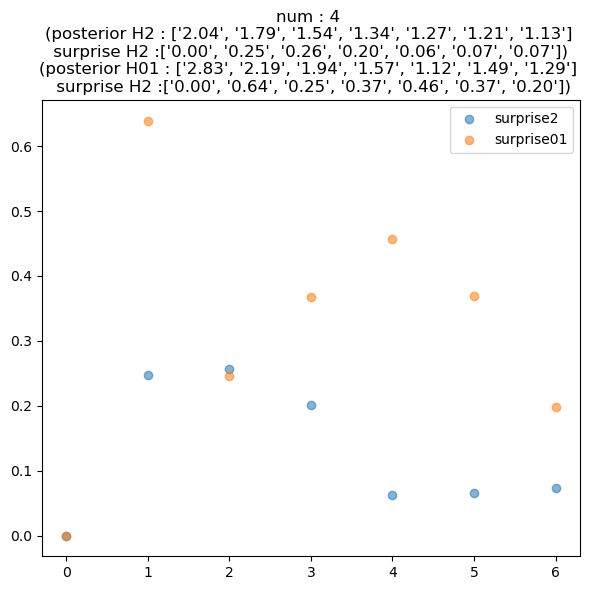

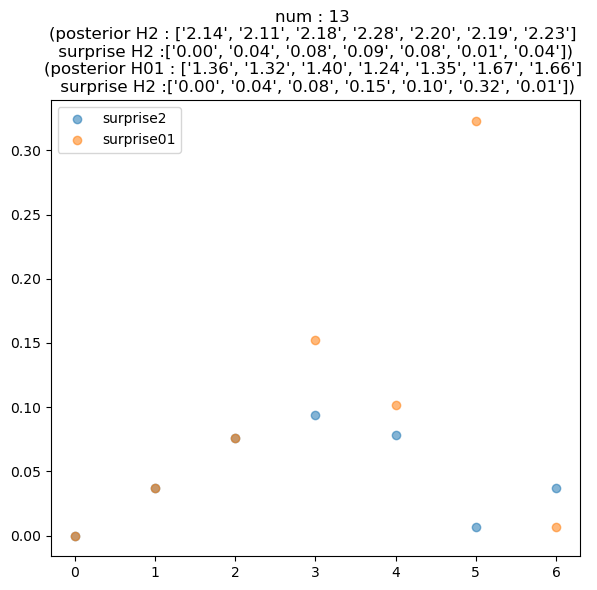

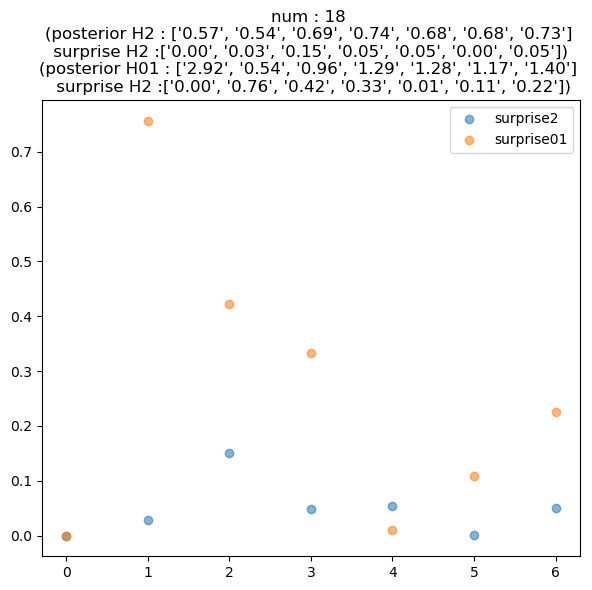

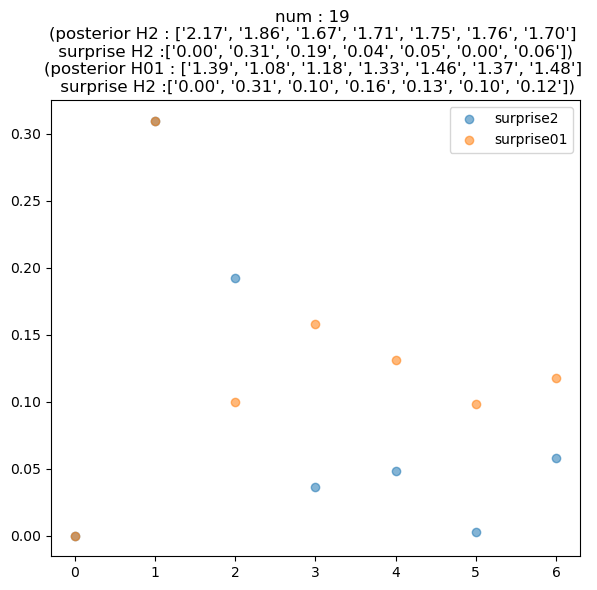

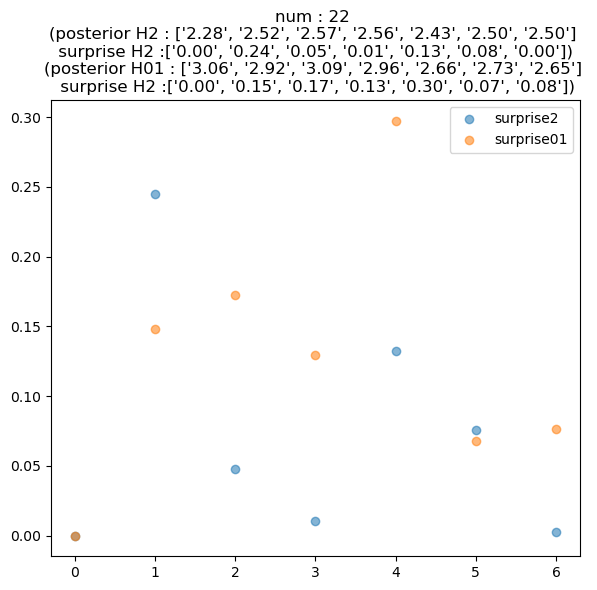

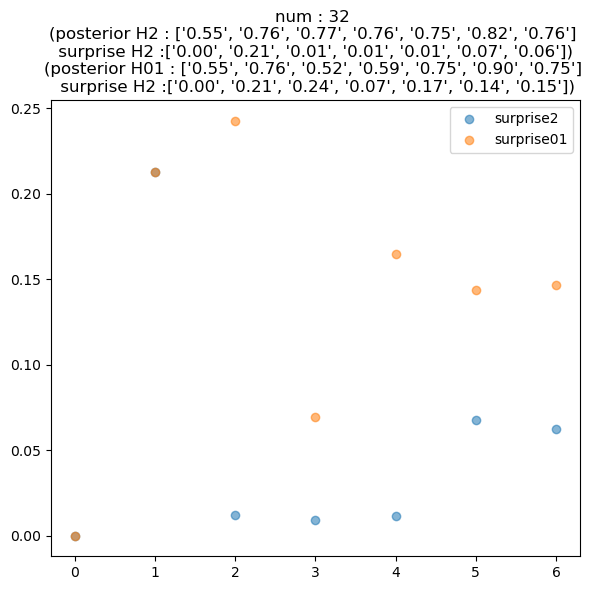

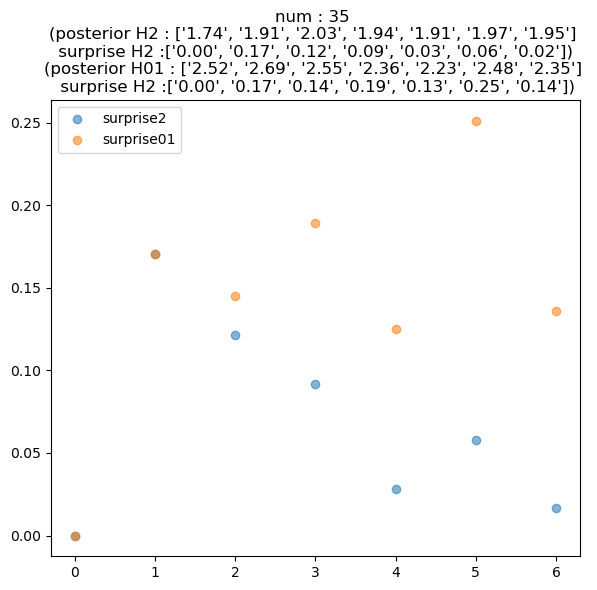

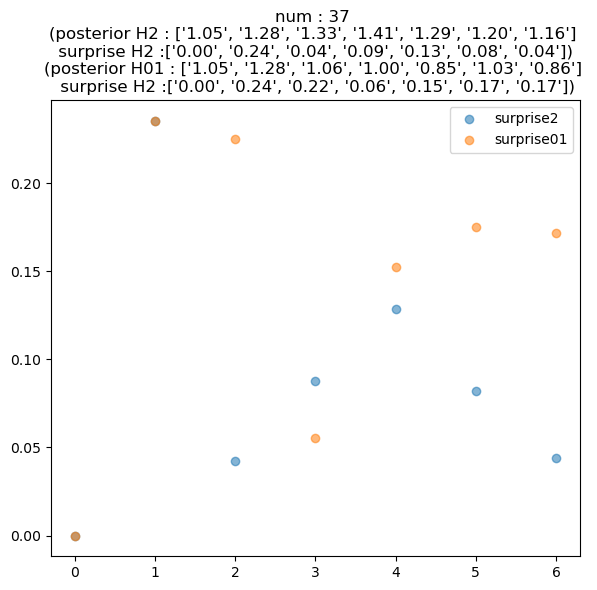

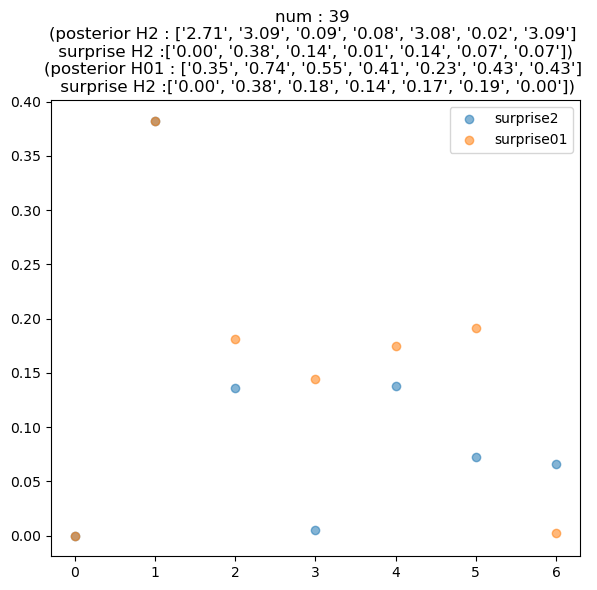

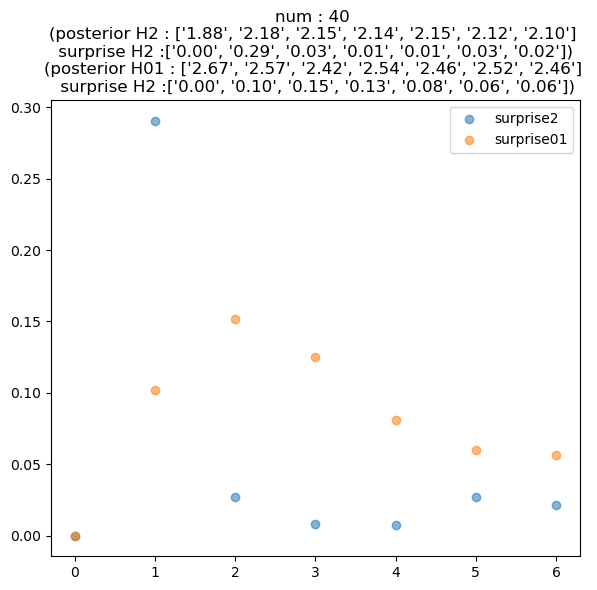

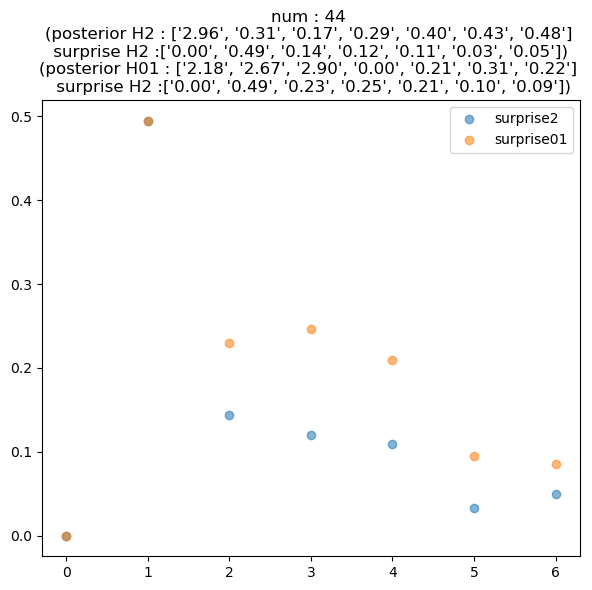

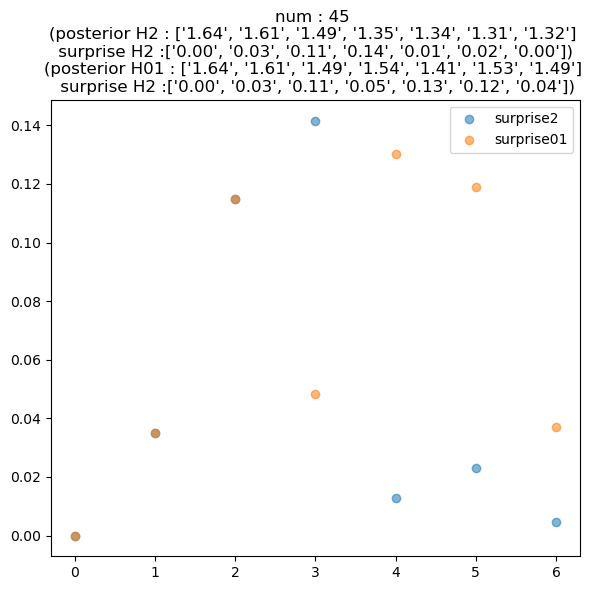

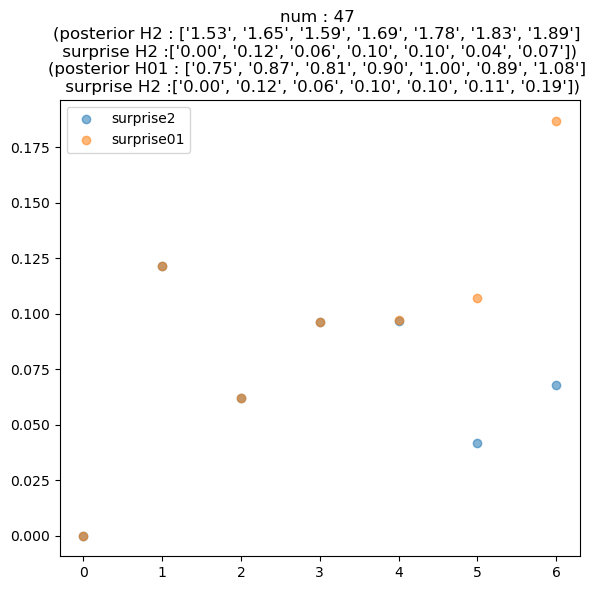

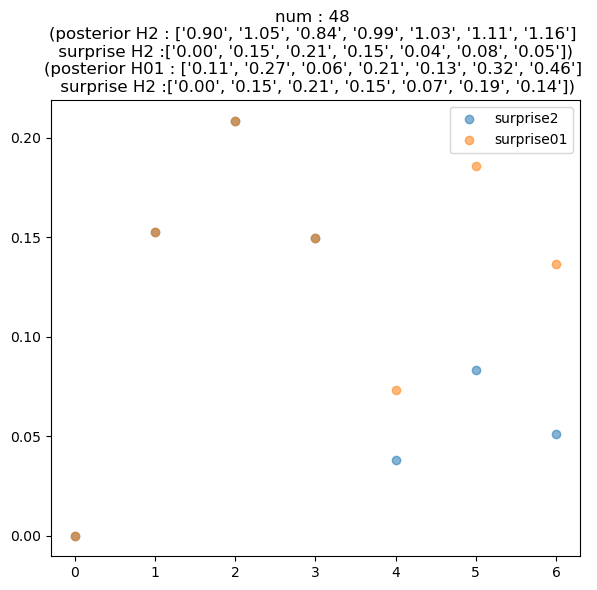

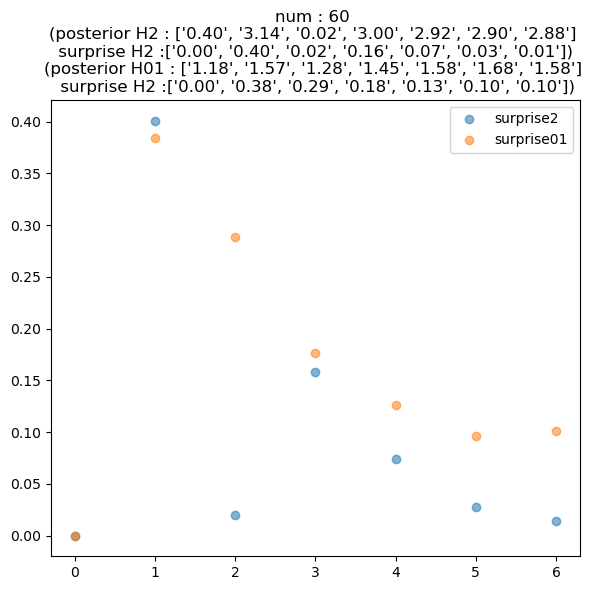

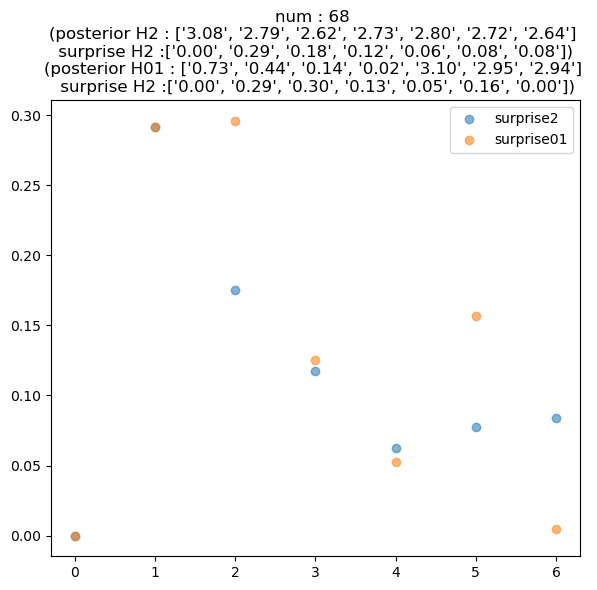

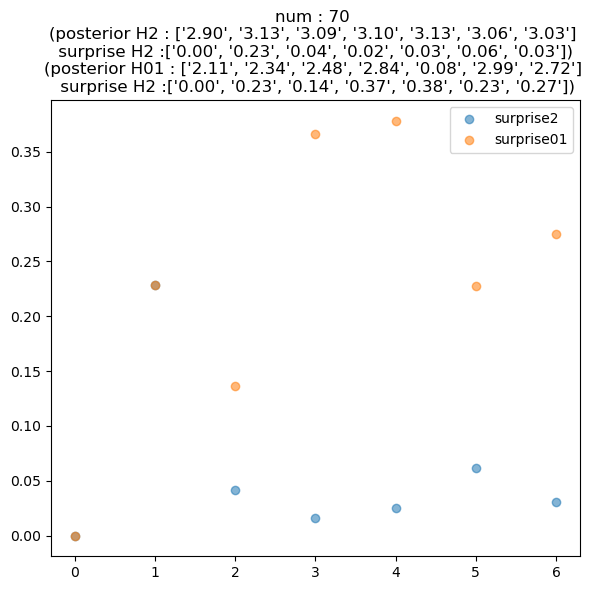

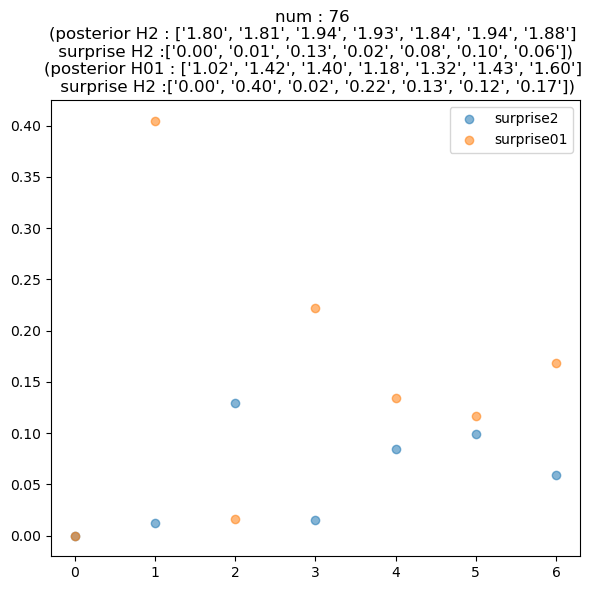

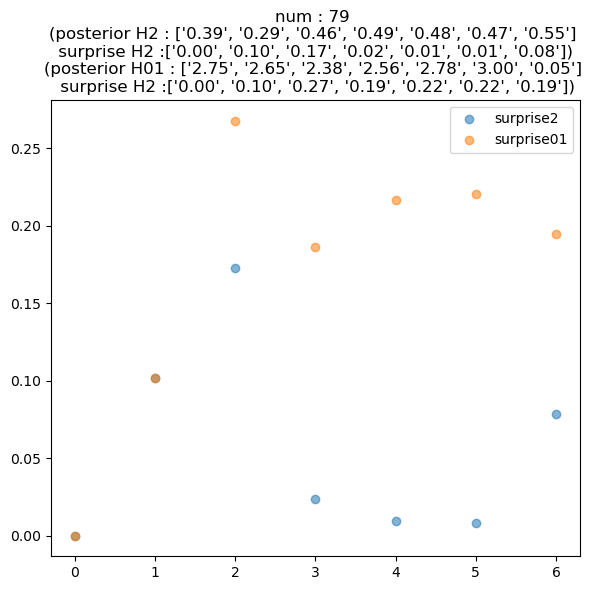

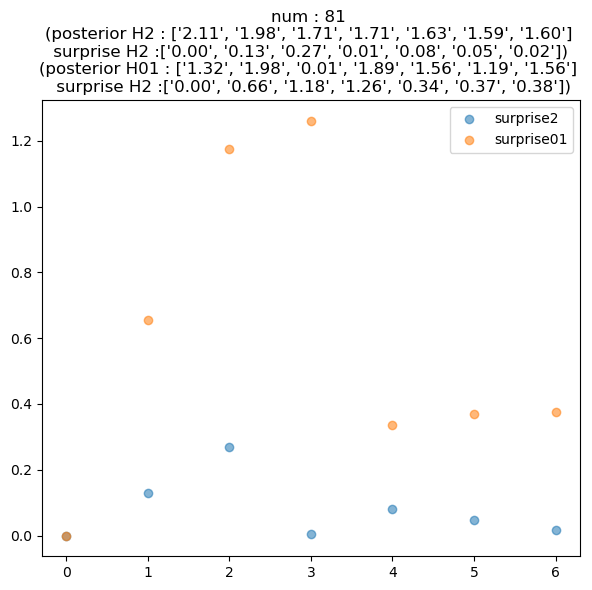

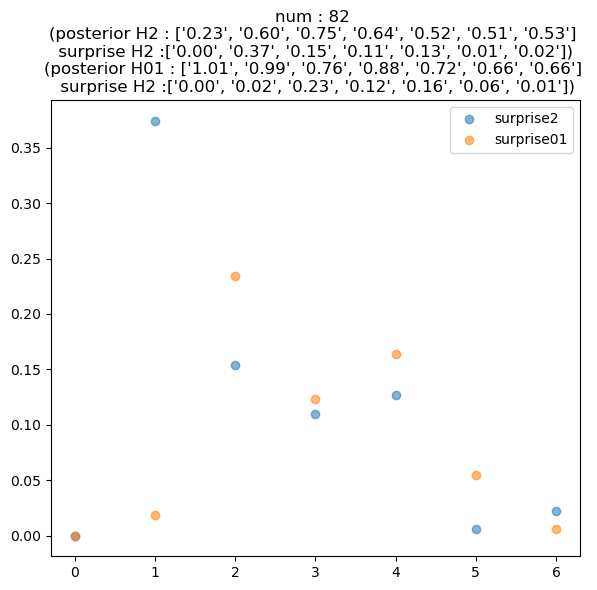

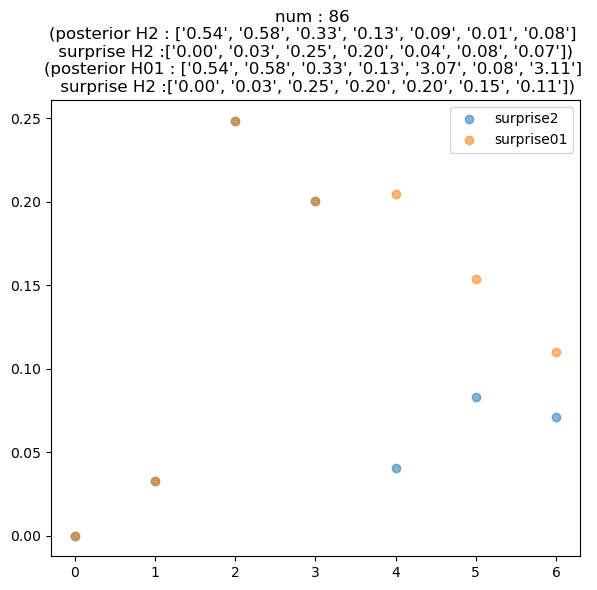

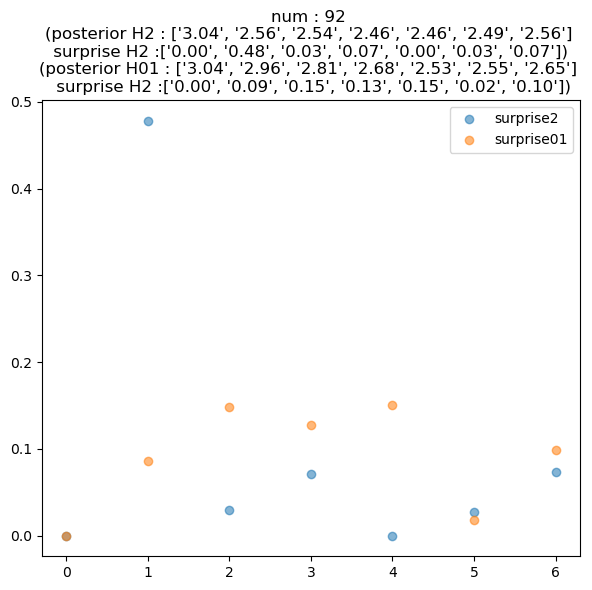

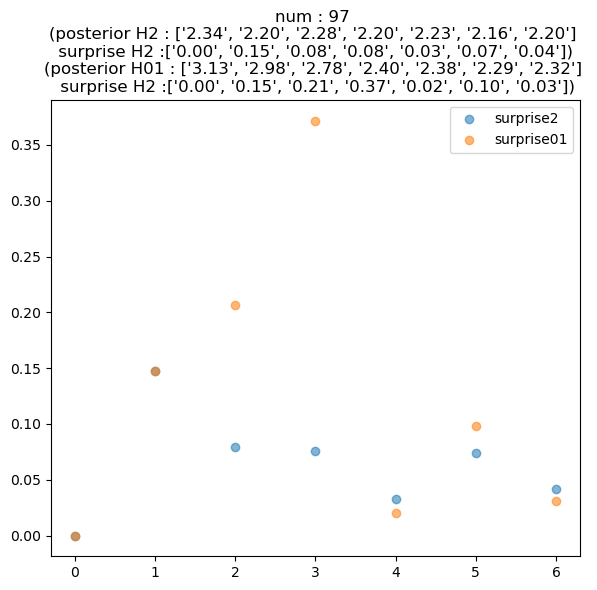

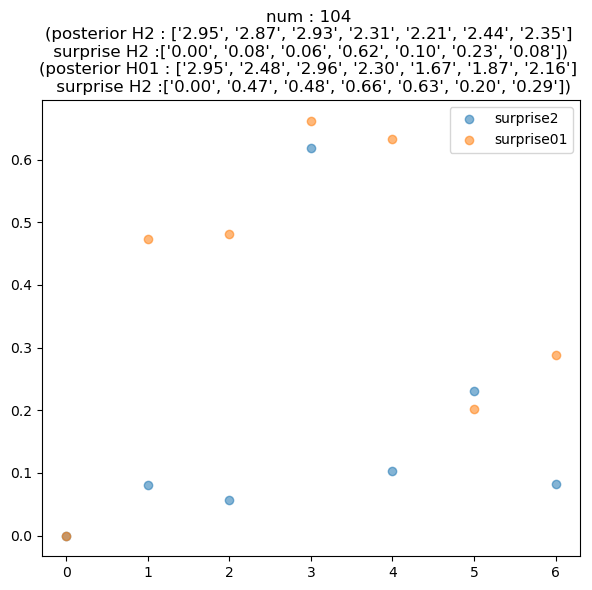

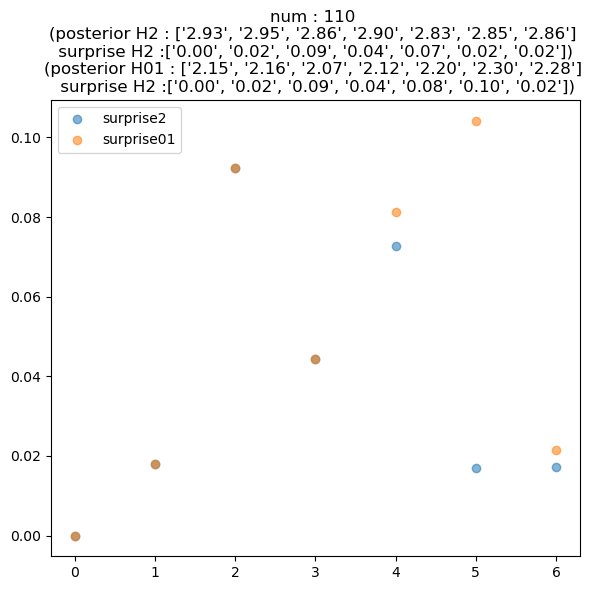

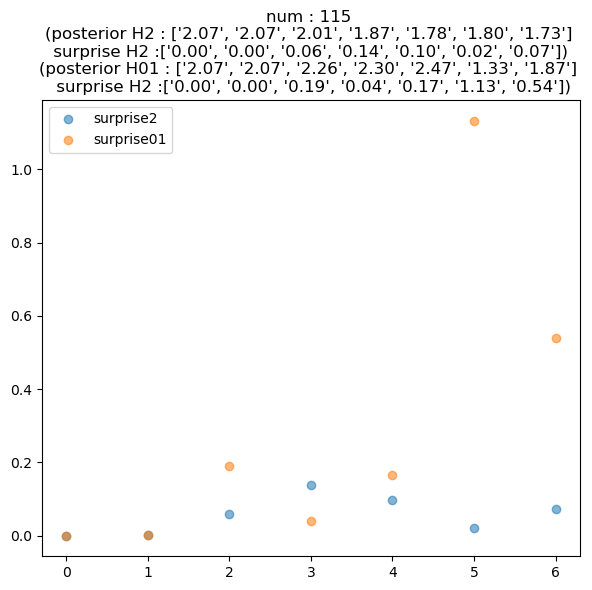

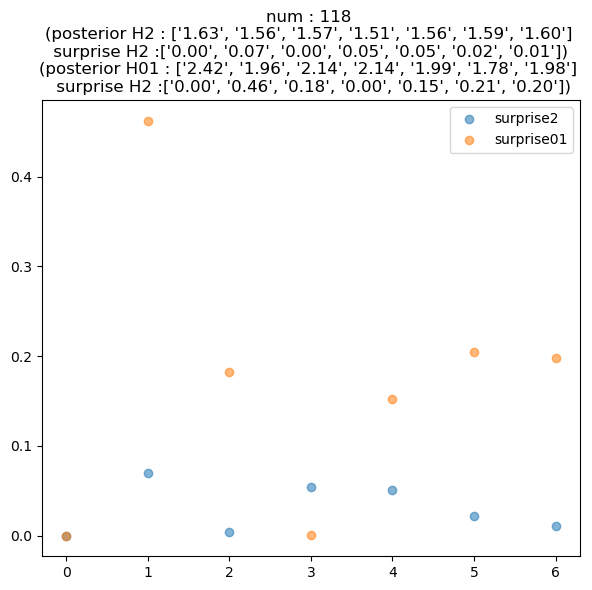

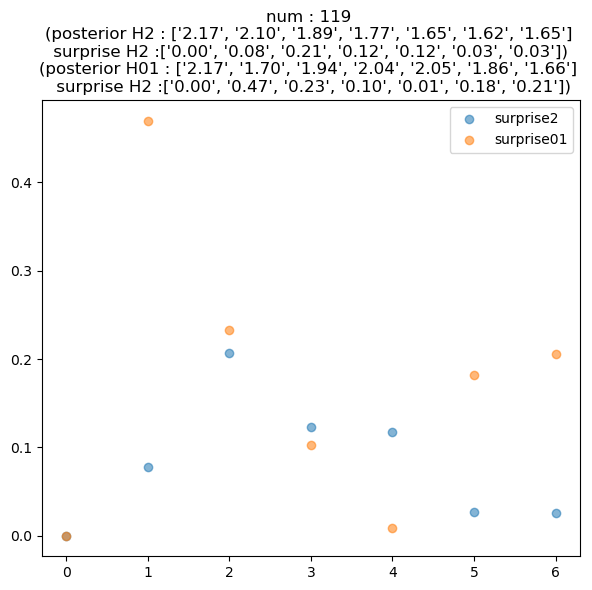

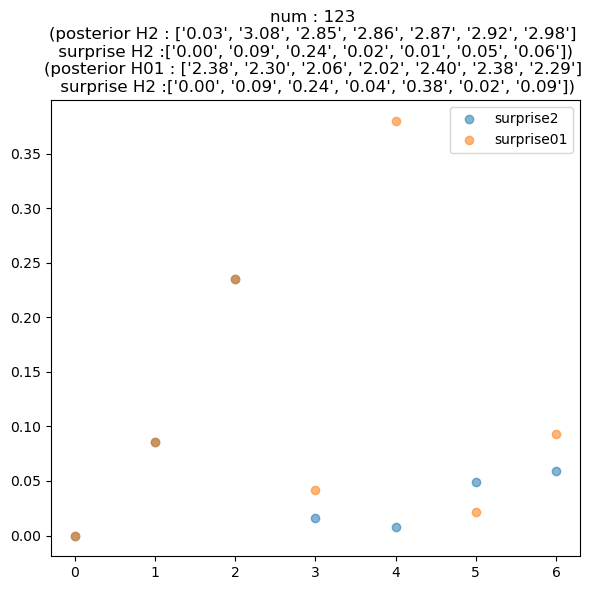

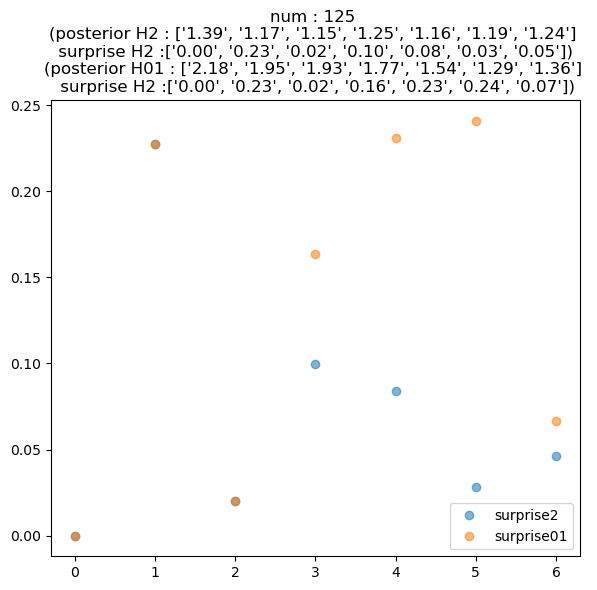

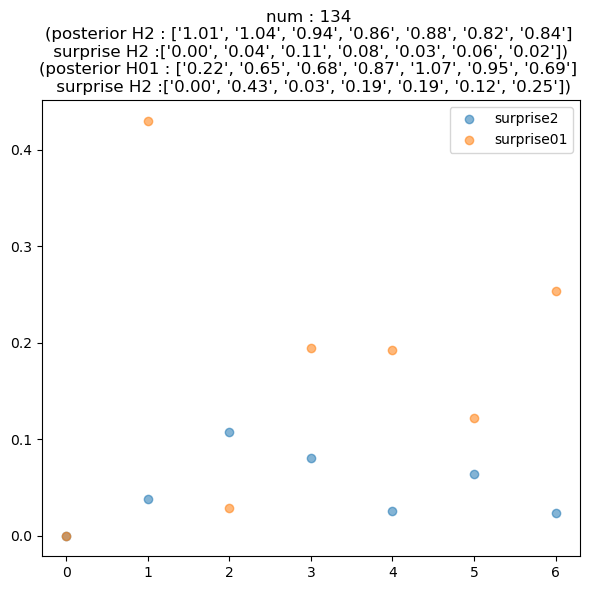

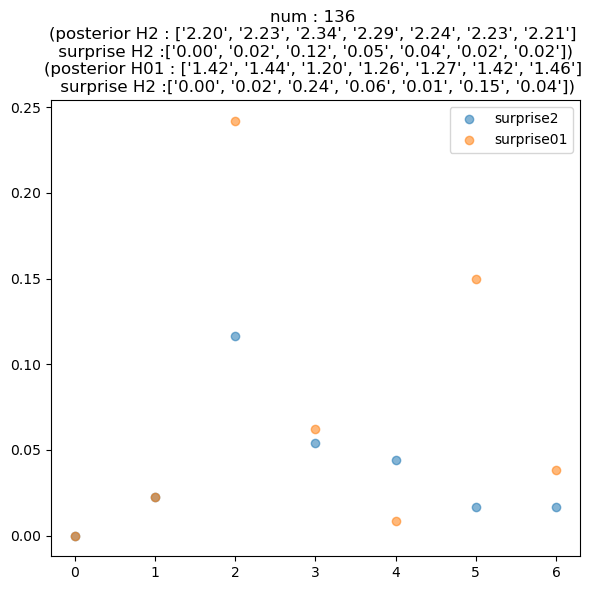

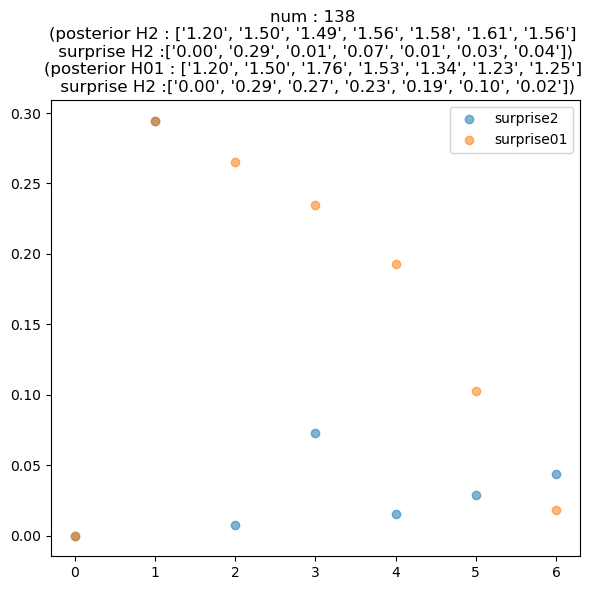

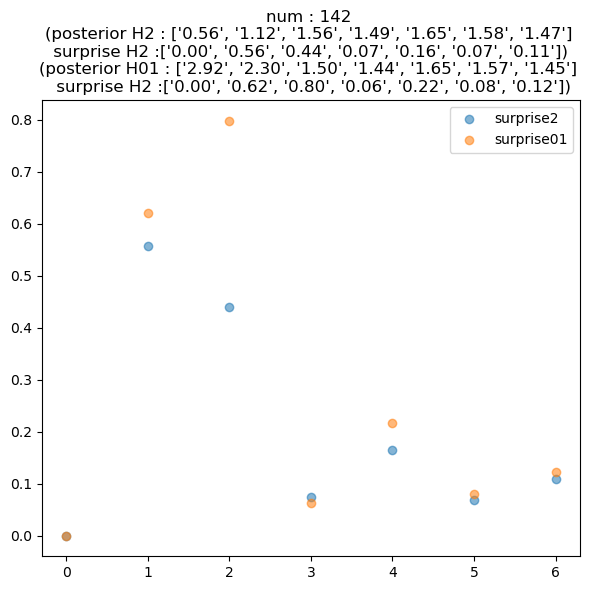

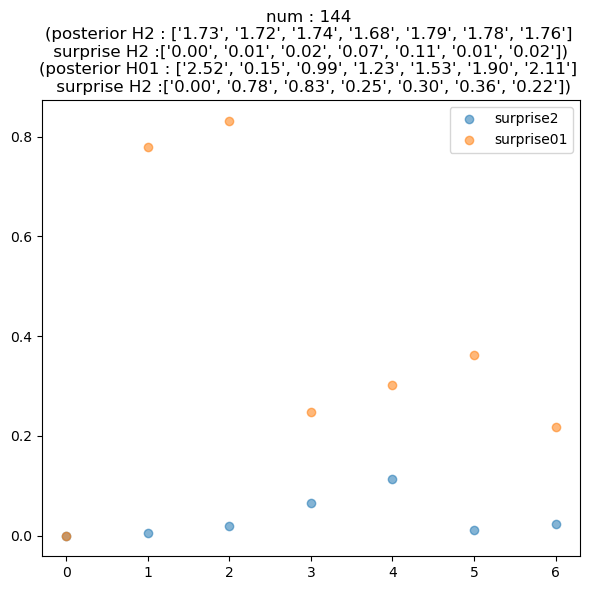

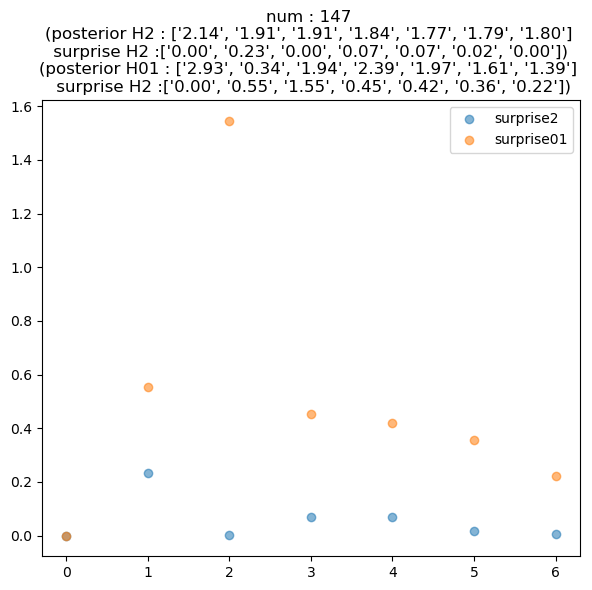

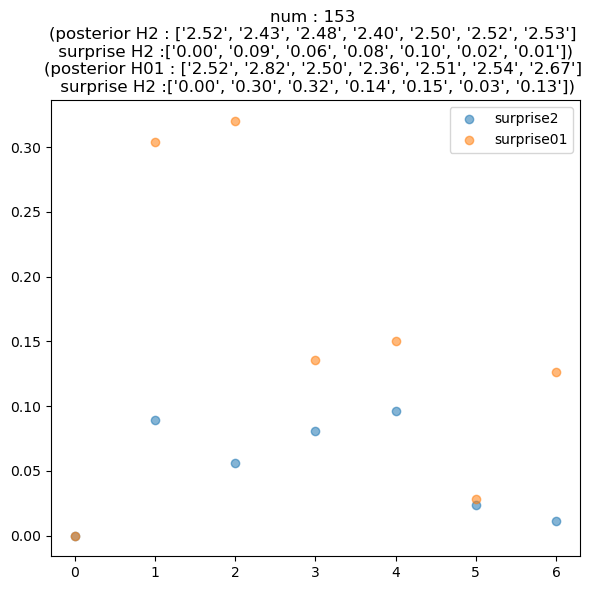

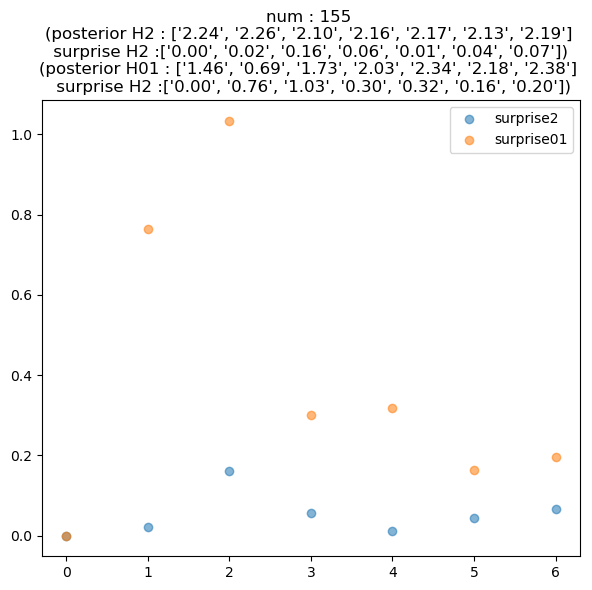

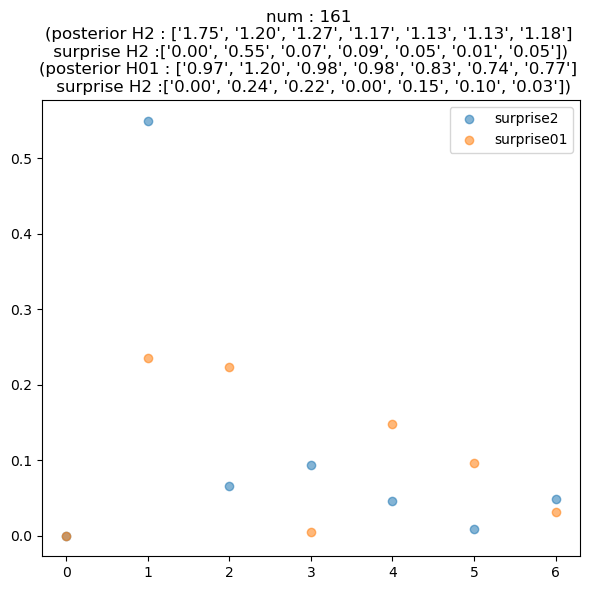

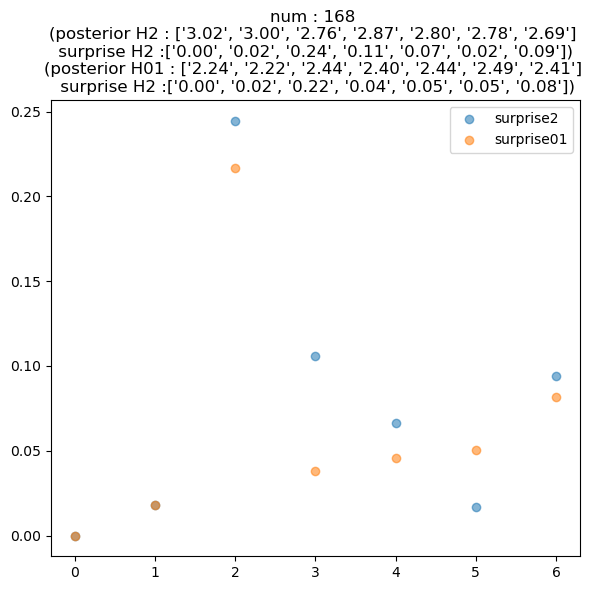

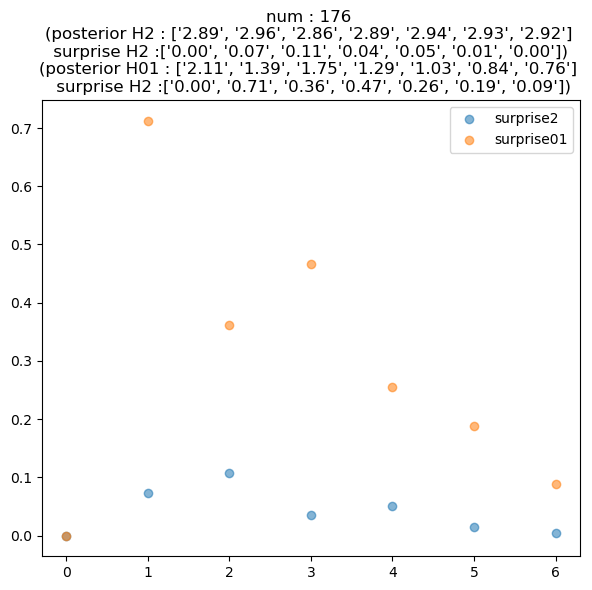

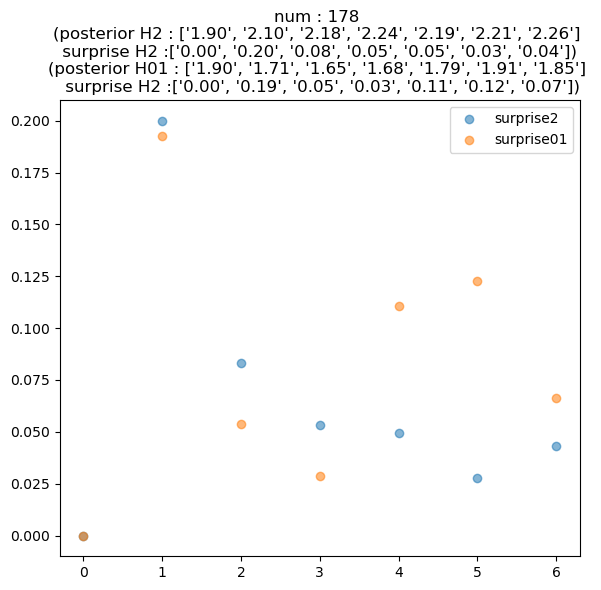

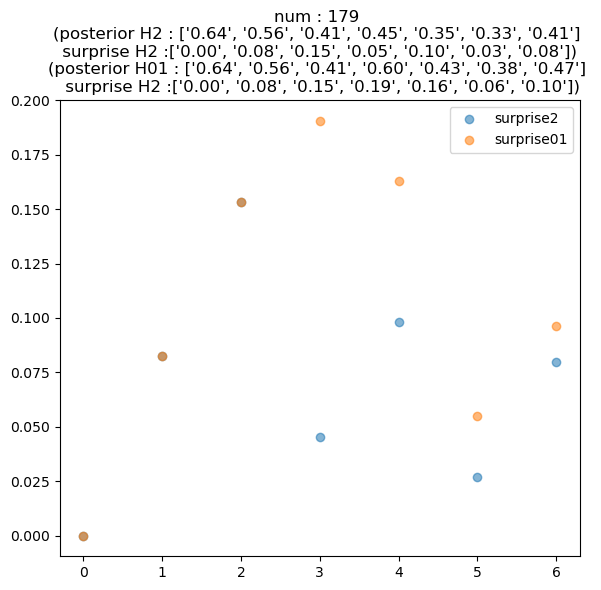

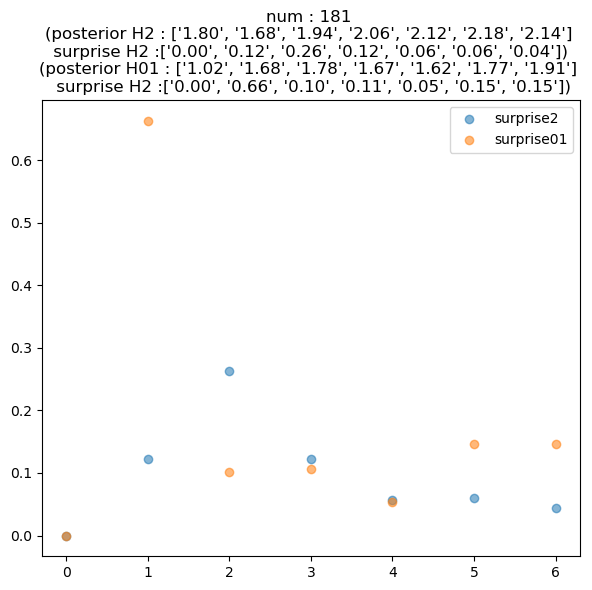

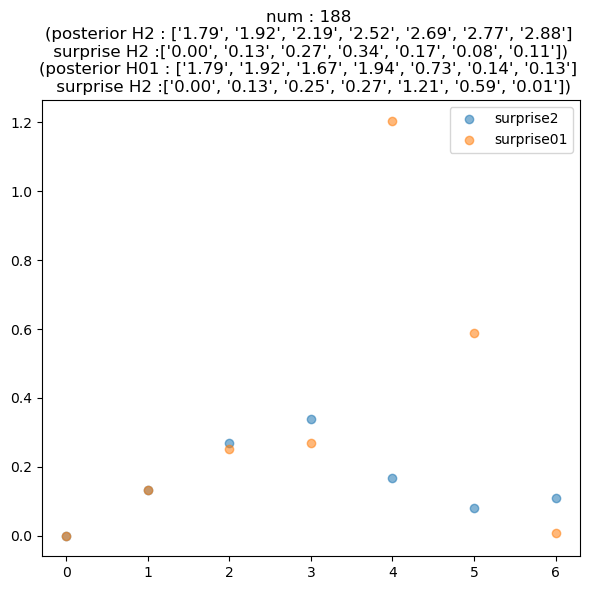

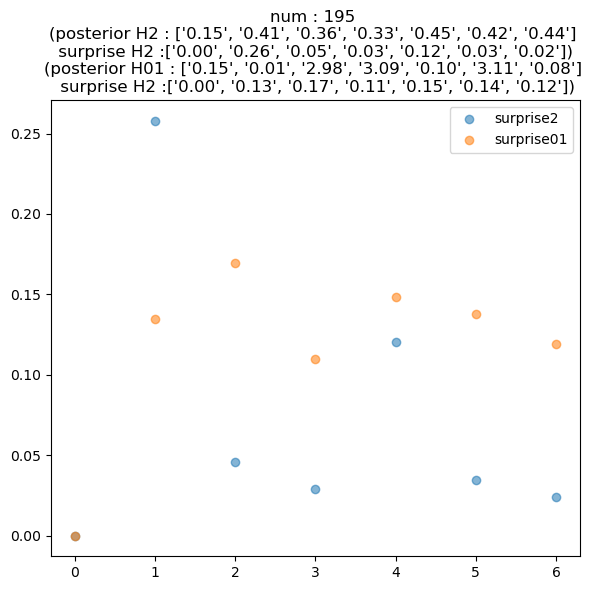

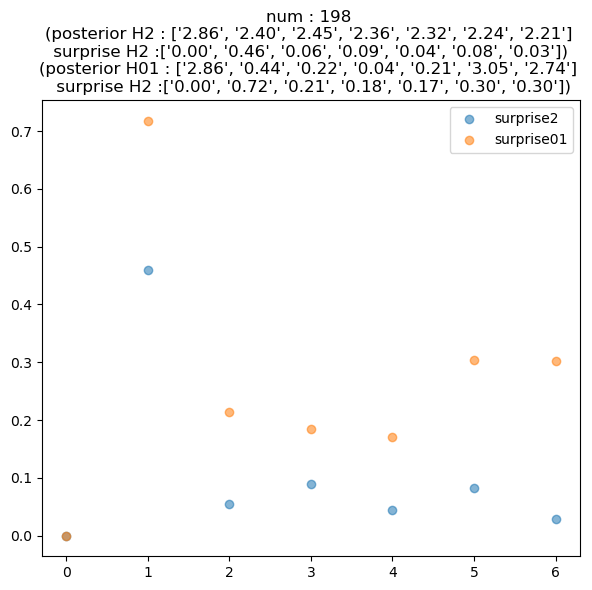

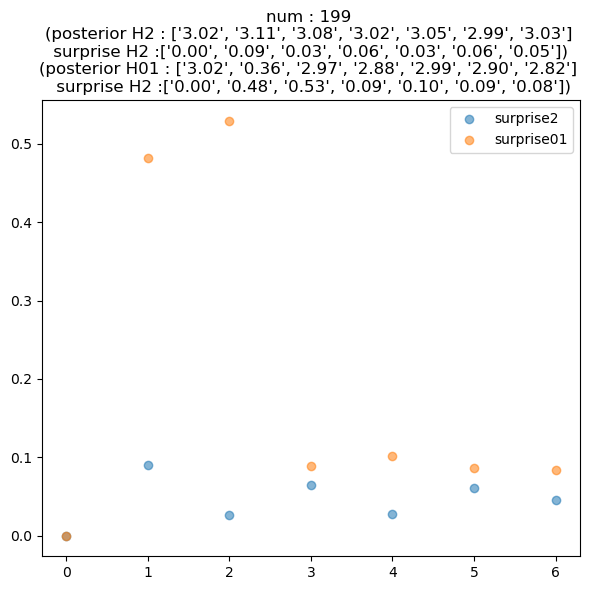

In [ ]:
# for the SUBoptimal model
for num in range(200) :
    list_presented_angles = df_radian["presented_angles"].iloc[num] 
    list_perceived_colors = df_radian["color_map_str"].iloc[num]

    target2, length2, posteriors2, surprise2 = optimal_model_poster_RH2(list_presented_angles,list_perceived_colors)
    target01, length01, posteriors01, surprise01 = optimal_model_poster_RH01(list_presented_angles,list_perceived_colors)

   
    if length2 > 6 : 
        # print("posterior", posteriors)
        # print("surprise", surprise)
        # print("presented angles",
        # list_presented_angles)
        # print("colors", list_perceived_colors)
        ### plot sur cercle 
        rounded_post2 = [f"{x:.2f}" for x in posteriors2]
        rounded_surprise2 = [f"{x:.2f}" for x in surprise2]
        
        rounded_post01 = [f"{x:.2f}" for x in posteriors01]
        rounded_surprise01 = [f"{x:.2f}" for x in surprise01]
        
        
        plt.figure(figsize=(6,6))
        plt.plot(surprise2, 'o', alpha=0.55, label="surprise2")
        plt.plot(surprise01, 'o', alpha=0.55, label="surprise01")

        # ax.scatter(posteriors, np.ones_like(posteriors),
        #    alpha=0.55, label="rotated")
        # ax.scatter(surprise, np.ones_like(surprise),
        #         alpha=0.55, label="surprise")
        # ax.scatter(list_presented_angles, np.ones_like(list_presented_angles),
        #         alpha=0.55, label="presented angles")

        # ax.set_yticklabels([])   # enlève les labels du rayon
        plt.title(f"num : {num} \n(posterior H2 : {rounded_post2} \n surprise H2 :{rounded_surprise2}) \n(posterior H01 : {rounded_post01} \n surprise H2 :{rounded_surprise01})")
        plt.legend()
        plt.tight_layout()
        # ax.set_title(f"num : {num}")
        plt.show()

In [58]:
dataW = pd.read_csv("/Users/elodiehusson/Desktop/Projet/comportement AVANT STAGE/Data/Poids/LucasBenjamin_5d684971f5868700184eab81.csv", skiprows=1, index_col=3)

df_filtered_W = dataW[dataW["stimulus_weights"].notna()]
df_filtered_W = df_filtered_W.drop(columns=["rt", "url", "time_elapsed", "internal_node_id", "success", "responses", "view_history", "response_rts", "key_press", "confidence", "correct", "trial_type", "stimulus"])
df_filtered_W.reset_index(drop=True, inplace=True)
df_filtered_W["length of sequence"] = df_filtered_W["presented_angles"].apply(lambda s: len(s.split(',')) if isinstance(s, str) else 0)
df_filtered_W['presented_angles'] = df_filtered_W['presented_angles'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered_W['stimulus_weights'] = df_filtered_W['stimulus_weights'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
df_filtered_W['score'] = df_filtered_W['score'].astype(int)
df_filtered_W = df_filtered_W.dropna(subset=["final_angle"])
df_filtered_W

def calculating_weights (angles, weights) :
    if len(angles) != len(weights):
        raise ValueError("The length of angles and weights must be the same.")

    right_angles = []
    for angle, weight in zip(angles, weights):
        if weight == 0.0 : 
            continue
        elif weight == 1.0 : 
            right_angles.append(angle)
        elif weight == 2.0 : 
            right_angles.append(angle)
            right_angles.append(angle)
    
    return right_angles  
def result_vector (angles, weights) :
    resulting_vector = 0
    for angle, weight in zip(angles, weights):
        resulting_vector+= weight* cmath.exp(complex(0,2  * angle))
        
    target = np.angle(resulting_vector)/2
    return target

df_radian_W = df_filtered_W.copy().drop(columns=["presented_angles", "final_angle", "target"])
df_radian_W['final_angle'] = np.deg2rad(df_filtered_W['final_angle'])
df_radian_W['presented_angles'] = df_filtered_W['presented_angles'].apply(
    lambda lst: np.deg2rad(np.array(lst, dtype=float)))

df_radian_W["target_degrees"] = df_filtered_W["target"]
df_radian_W['target'] = df_radian_W.apply(lambda row: result_vector(row['presented_angles'], row['stimulus_weights']),axis=1)
df_radian_W['target_numbers'] = df_radian_W.apply(lambda row: calculating_weights(row['presented_angles'], row['stimulus_weights']),axis=1).apply(CircularMean)

df_radian_W["target_wo_weights"] = df_radian_W['presented_angles'].apply(lambda angles: CircularMean(angles))
df_radian_W["mean_weights"] = df_radian_W["stimulus_weights"].apply(CircularMean) 
# circular error between the angle given by the subject, and the angle he should have given
df_radian_W["error_to_target"] = circular_error(df_radian_W["final_angle"], df_radian_W["target"])

# circular mean and circular error between the angle the subjects gave, and what the subjectq would have answered if they had ignored the rotations
df_radian_W["error_wo_weights"] = circular_error(df_radian_W["final_angle"], df_radian_W["target_wo_weights"])  

df_radian_W



,trial_rt,stimulus_weights,score,length of sequence,final_angle,presented_angles,target_degrees,target,target_numbers,target_wo_weights,mean_weights,error_to_target,error_wo_weights
0,2780.0,"[1.0, 1.0, 2.0, 2.0, 2.0, 0.0, 2.0]",10,7,-0.117872,"[0.12108768057891404, 0.781708456549988, -0.53...",178.492356,-0.026313,-0.026313,0.120125,-1.341401,-0.091559,-0.237997
1,2337.0,"[1.0, 2.0, 1.0, 2.0, 1.0, 2.0, 0.0]",10,7,-1.314491,"[1.9462831368502125, 1.3985924133208305, 2.994...",107.650829,-1.296717,-1.296717,-1.134756,1.468706,-0.017774,-0.179735
2,2685.0,"[1.0, 2.0, 0.0, 0.0, 1.0]",8,5,0.327860,"[0.1350204714002297, 0.1285814226756066, 1.858...",11.420378,0.198318,0.198318,0.250418,0.559956,0.129543,0.077442
3,2479.0,"[1.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0]",10,7,0.112111,"[0.5174524196957739, 0.7945250059370562, -0.02...",5.326969,0.165554,0.165554,-0.099761,0.609461,-0.053443,0.211872
4,1961.0,"[1.0, 1.0, 1.0, 2.0, 0.0, 2.0, 1.0]",10,7,-1.285124,"[2.187513010606344, 1.62444925683485, 1.651206...",103.815886,-1.329664,-1.329664,-1.468077,1.159584,0.044540,0.182953
...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,1139.0,"[1.0, 2.0, 1.0]",0,3,0.980262,"[2.067700178159714, 3.4204345654002797, 2.0394...",156.845890,-0.404115,-0.404115,-0.912249,1.260581,1.384378,-1.249081
196,1385.0,"[1.0, 1.0, 1.0, 1.0, 2.0]",10,5,2.539566,"[2.334769982683555, 2.668866152158468, 1.93532...",150.605618,-0.513029,-0.513029,-0.658273,1.124239,-0.088998,0.056246
197,1133.0,"[1.0, 2.0, 0.0, 2.0, 2.0, 2.0, 0.0]",8,7,1.937970,"[1.4688733440843358, 2.0596092167060145, 1.157...",118.090890,-1.080518,-1.080518,-1.421746,-1.011861,-0.123105,0.218124
198,1527.0,"[1.0, 1.0, 0.0, 2.0, 0.0, 2.0, 2.0]",10,7,1.798724,"[1.0324831521524673, 2.0788013835086137, 1.774...",104.564034,-1.316606,-1.316606,-1.438944,-1.311917,-0.026262,0.096076


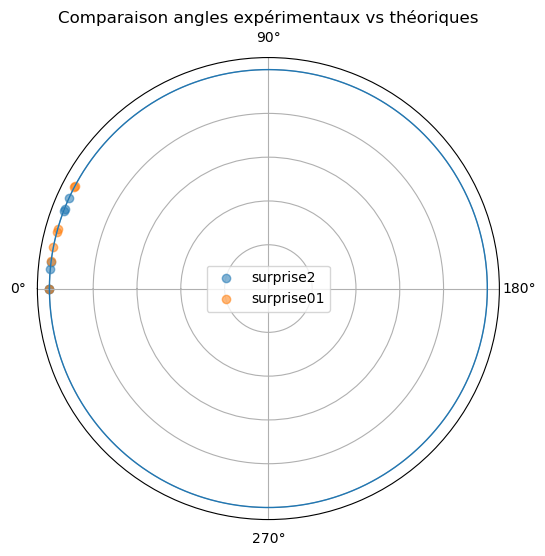

In [63]:
# for the SUBoptimal model
num = 1
list_presented_angles = df_radian_W["presented_angles"].iloc[num] 
list_perceived_colors = df_radian_W["stimulus_weights"].iloc[num]

target2, length2, posteriors2, surprise2 = optimal_model_poster_WH2(list_presented_angles,list_perceived_colors)
target01, length01, posteriors01, surprise01 = optimal_model_poster_WH01(list_presented_angles,list_perceived_colors)

# print("posterior", posteriors)
# print("surprise", surprise)
# print("presented angles", list_presented_angles)
# print("colors", list_perceived_colors)

### plot sur cercle 

fig = plt.figure(figsize=(6,6))
ax = plt.subplot(111, polar=True)

ax.set_theta_zero_location("W")   
ax.set_theta_direction(-1)        # sens horaire

# ---- CERCLE TRIGONOMÉTRIQUE ----
theta = np.linspace(0, np.pi*2, 400)
ax.plot(theta, np.ones_like(theta), linewidth=1)  # cercle unité

# labels angulaires
ax.set_thetagrids(
    angles=[0, 90, 180, 270],
    labels=["0°", "90°", "180°", "270°"]

)

# ---- TES DONNÉES ----
# x = [20, 40, 60, 120, 100 ]
# ax.scatter(posteriors2, np.ones_like(posteriors),
#            alpha=0.55, label="Experimentaux")
ax.scatter(surprise2, np.ones_like(surprise2),
           alpha=0.55, label="surprise2")
ax.scatter(surprise01, np.ones_like(surprise01),
           alpha=0.55, label="surprise01")


# ax.scatter(list_presented_angles, np.ones_like(list_presented_angles),
#            alpha=0.55, label="presented angles")

ax.set_yticklabels([])   # enlève les labels du rayon
ax.set_title("Comparaison angles expérimentaux vs théoriques")
ax.legend()

plt.show()


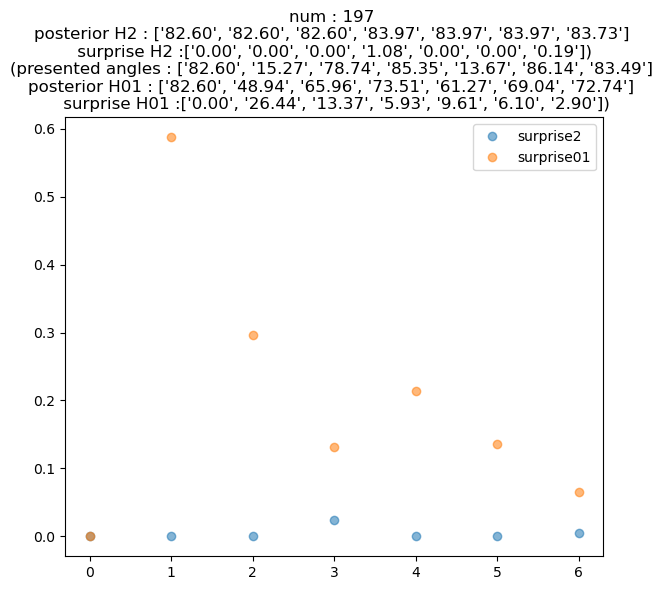

72.74086311435464


[1.0, 0.0, 0.0, 1.0, 0.0, 0.0, 2.0]

In [69]:

list_presented_angles = df_radian_W["presented_angles"].iloc[84] 
list_perceived_colors = df_radian_W["stimulus_weights"].iloc[84]
target2, length2, posteriors2, surprise2 = optimal_model_poster_WH2(list_presented_angles,list_perceived_colors)
target01, length01, posteriors01, surprise01 = optimal_model_poster_WH01(list_presented_angles,list_perceived_colors)

rounded_post2 = [f"{np.rad2deg(x):.2f}" for x in posteriors2]
rounded_surprise2 = [f"{x*45:.2f}" for x in surprise2]
rounded_post01 = [f"{np.rad2deg(x):.2f}" for x in posteriors01]
rounded_surprise01 = [f"{x*45:.2f}" for x in surprise01]
list_presented_angles = [f"{np.rad2deg(x):.2f}" for x in list_presented_angles]

plt.figure(figsize=(6,6))
plt.plot(surprise2, 'o', alpha=0.55, label="surprise2")
plt.plot(surprise01, 'o', alpha=0.55, label="surprise01")
plt.title(f"num : {num} \nposterior H2 : {rounded_post2} \n surprise H2 :{rounded_surprise2}) \n(presented angles : {list_presented_angles} \nposterior H01 : {rounded_post01} \n surprise H01 :{rounded_surprise01})")
plt.legend()
plt.tight_layout()
# ax.set_title(f"num : {num}")
plt.show()
print(np.rad2deg(target01))
list_perceived_colors

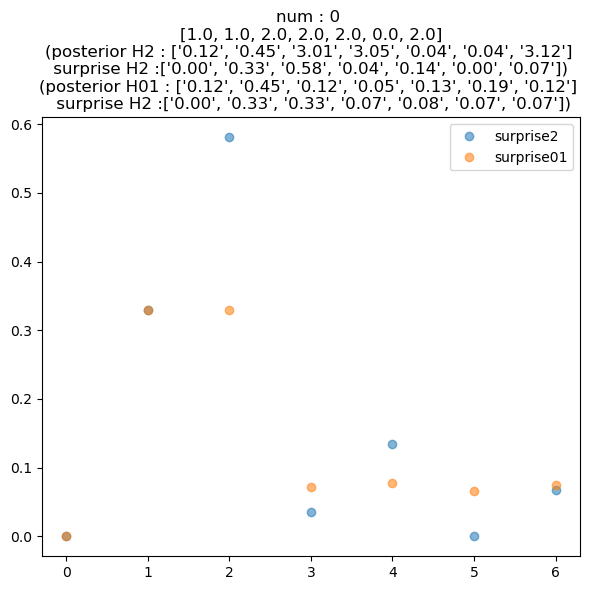

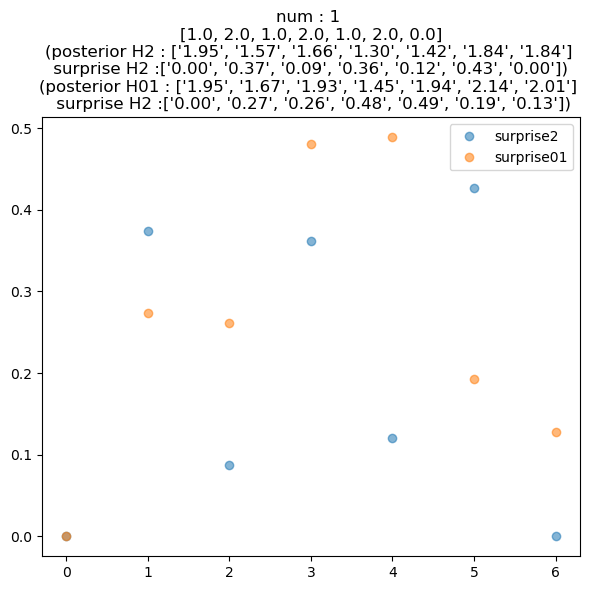

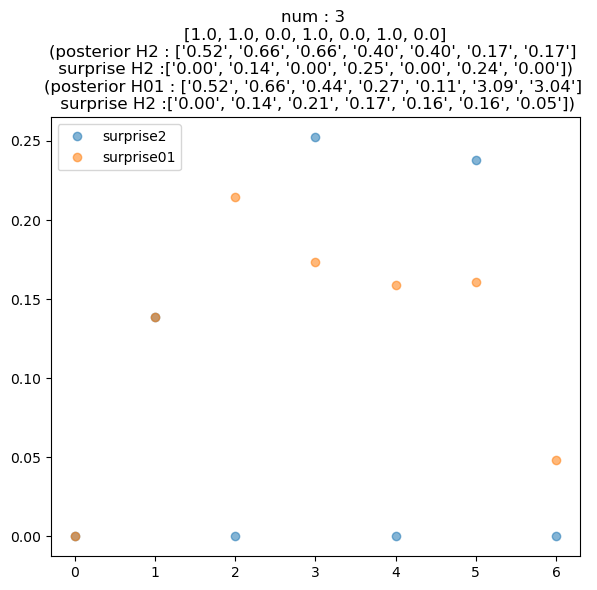

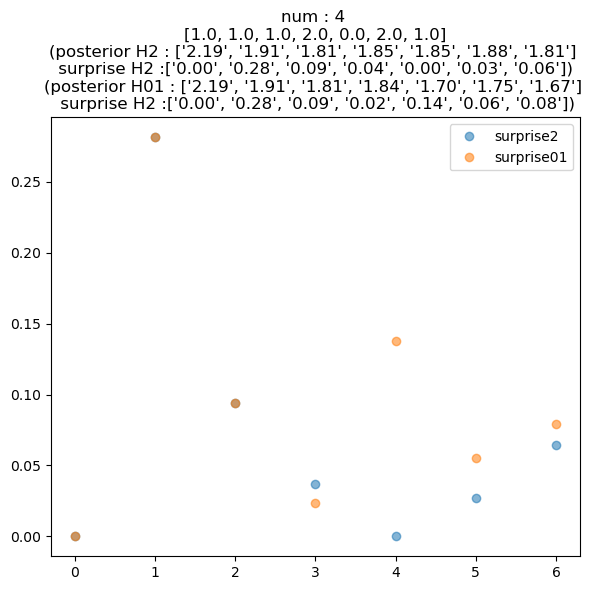

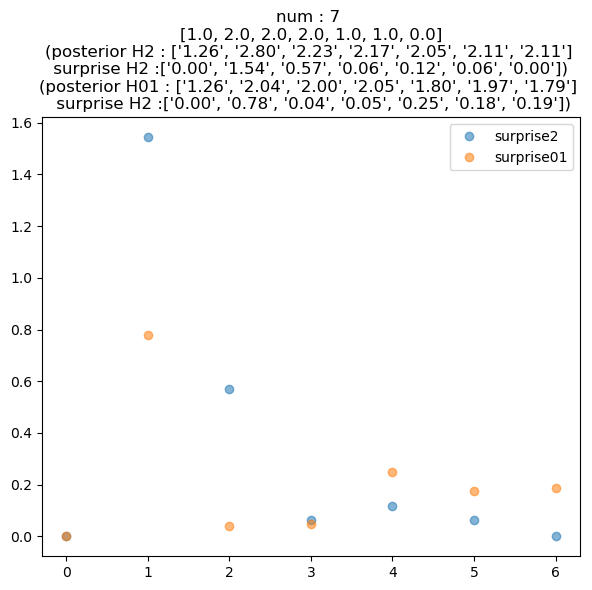

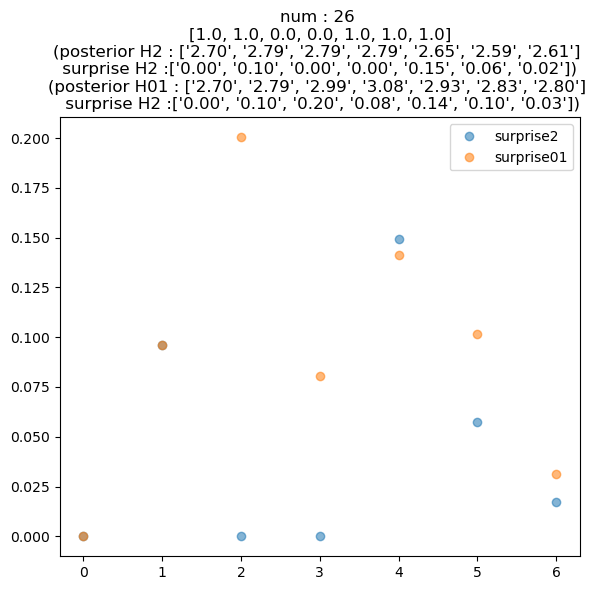

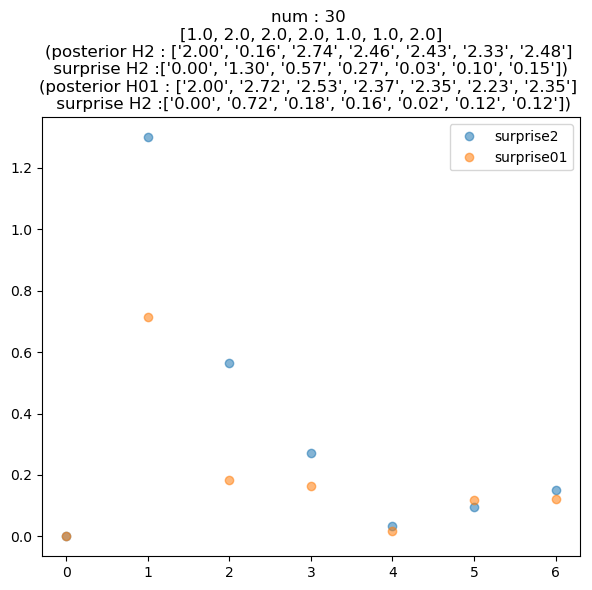

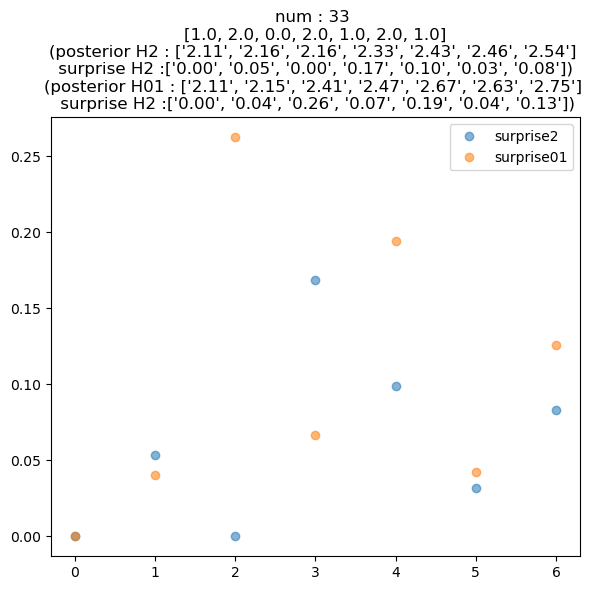

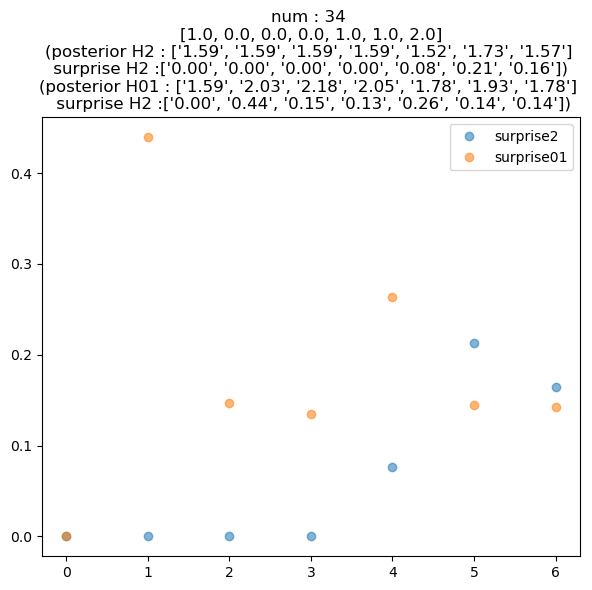

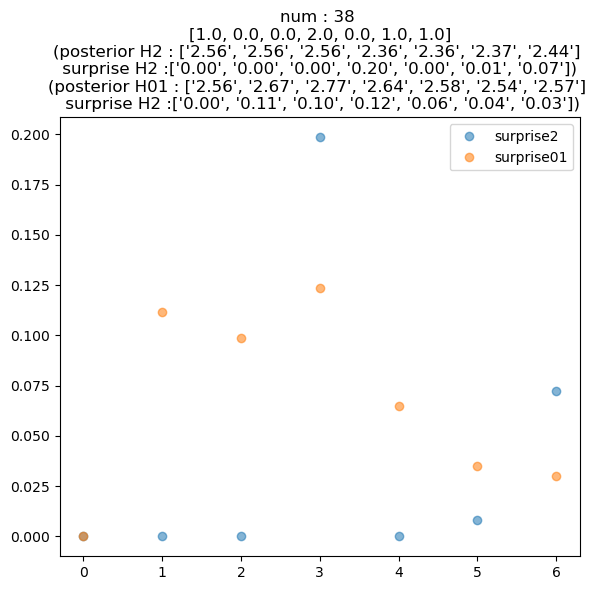

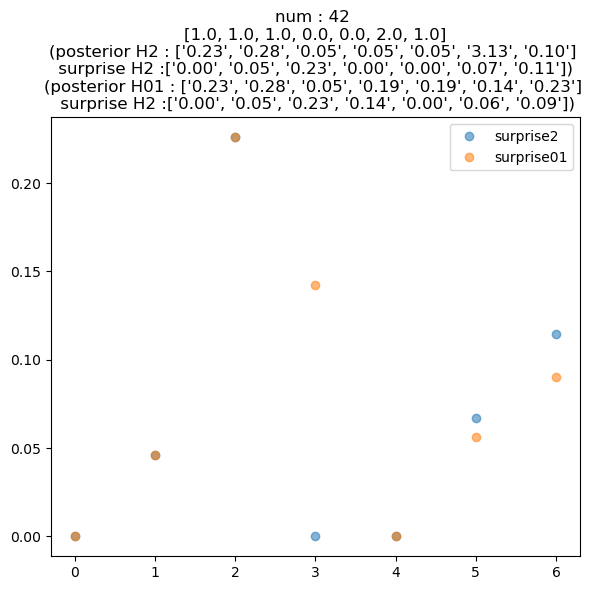

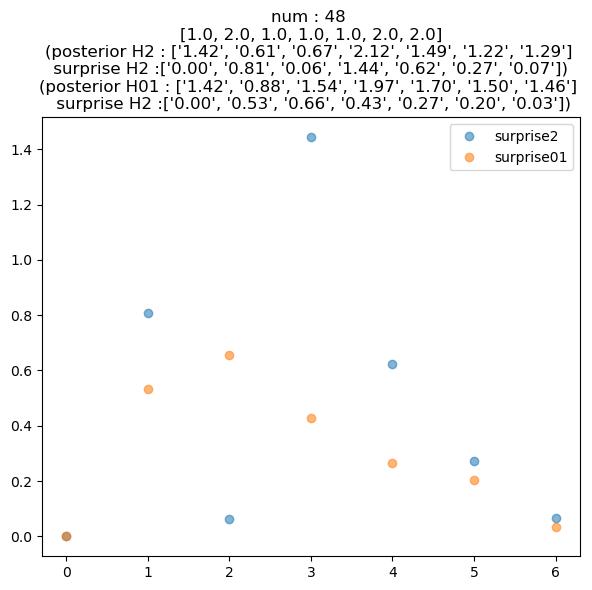

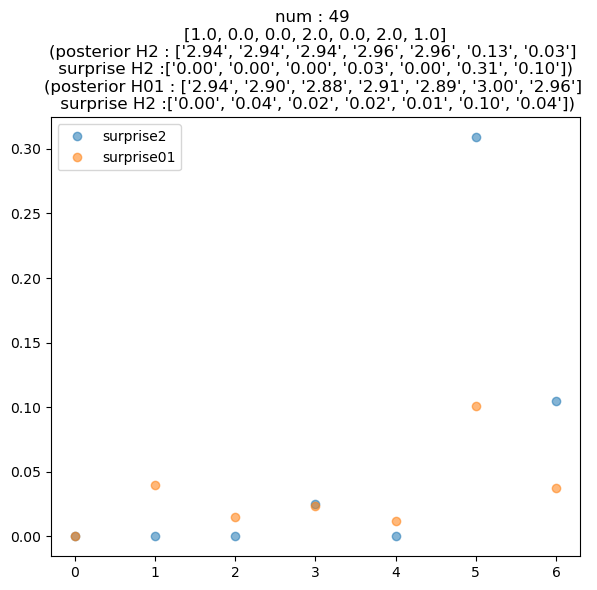

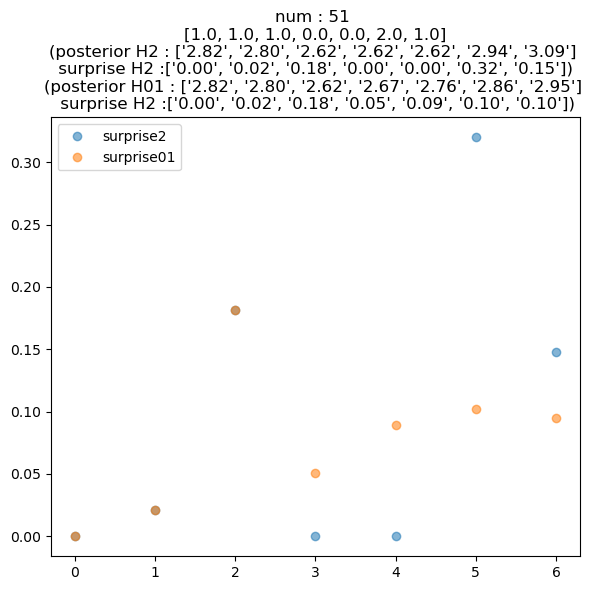

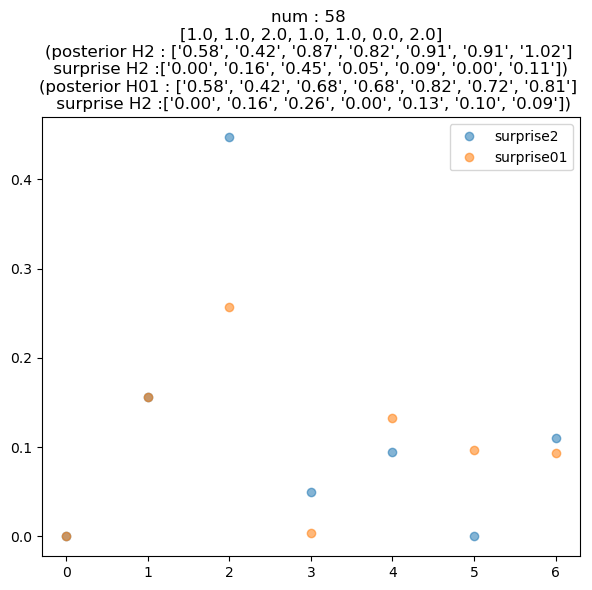

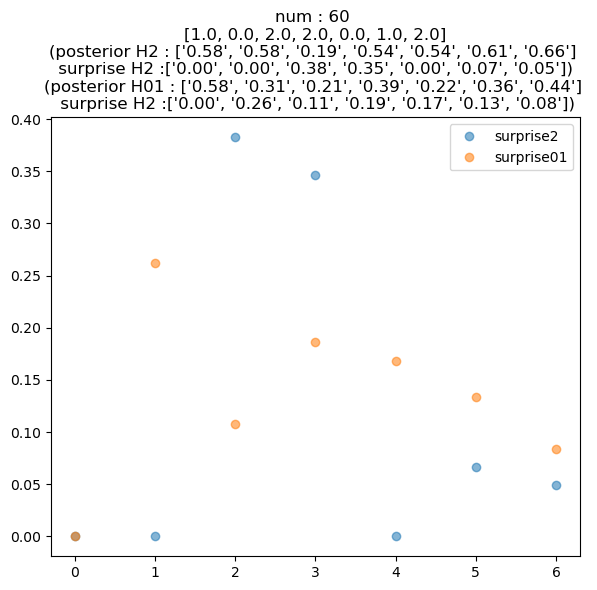

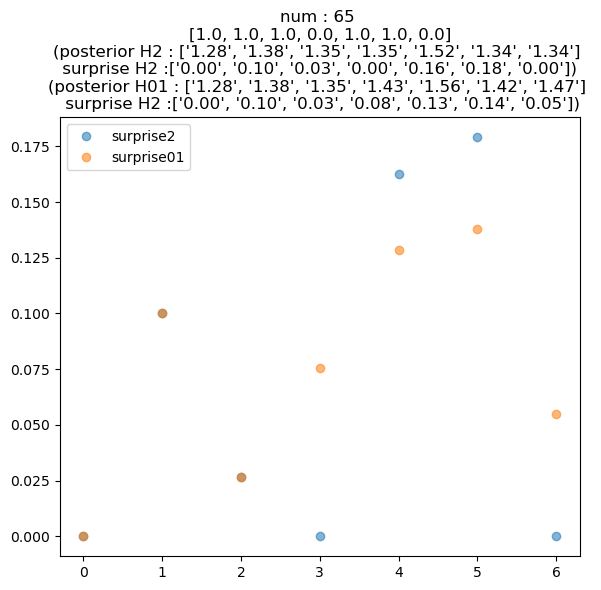

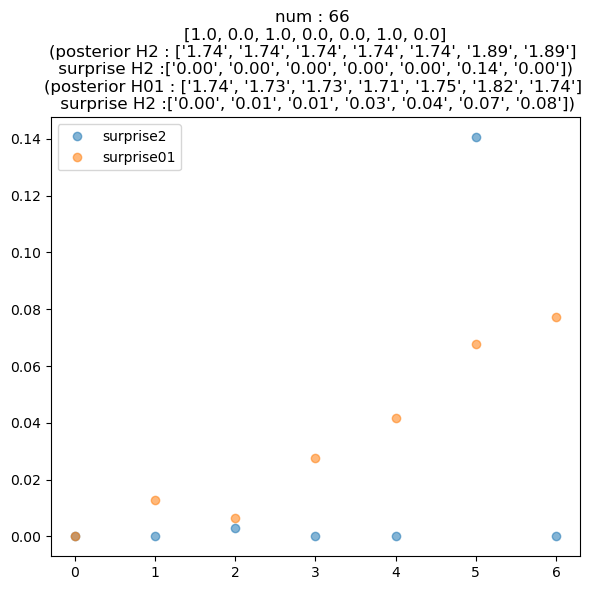

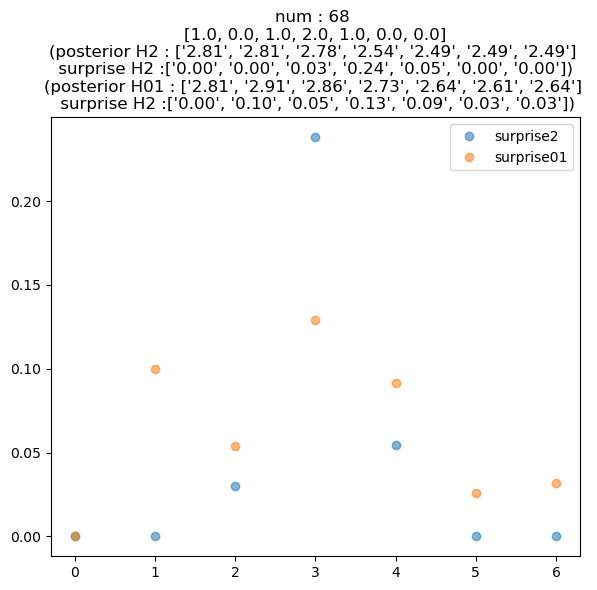

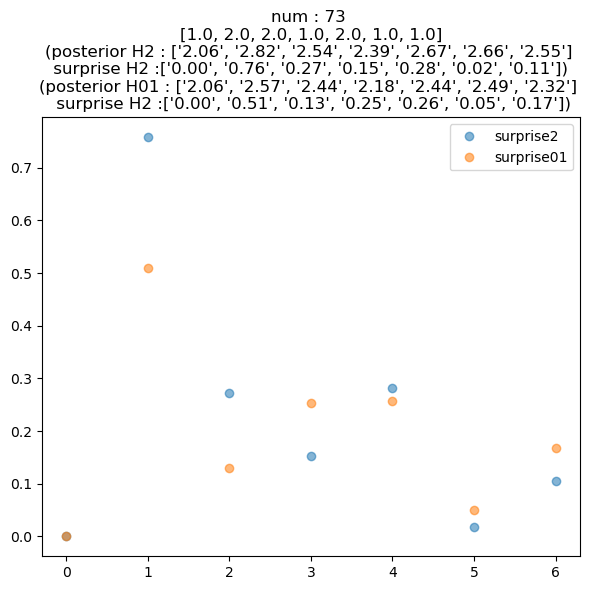

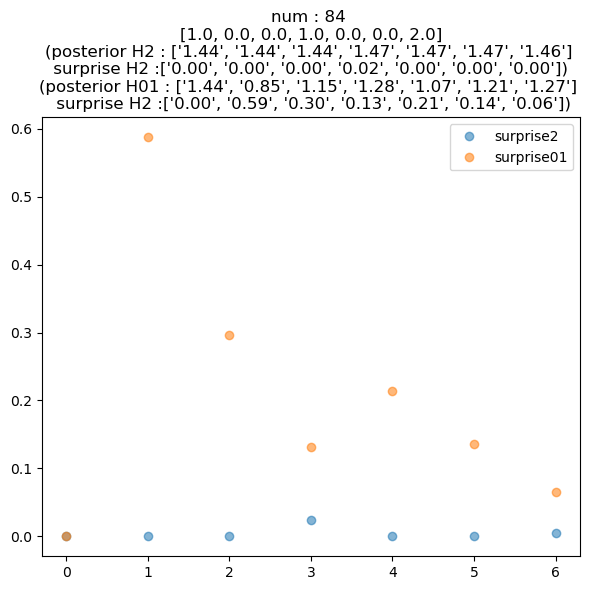

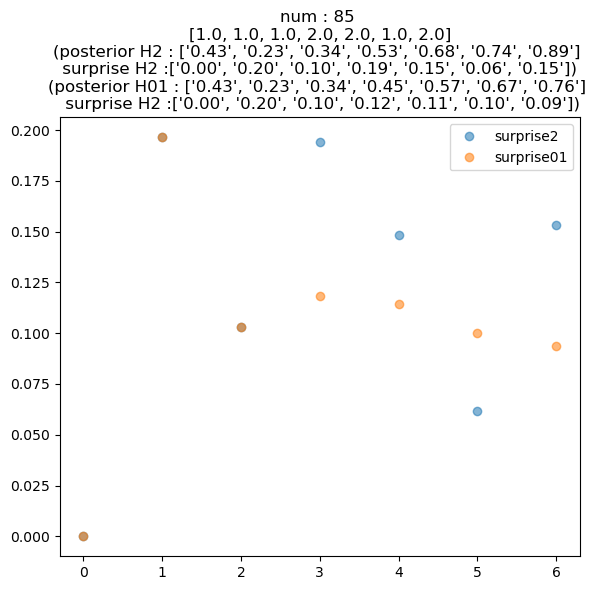

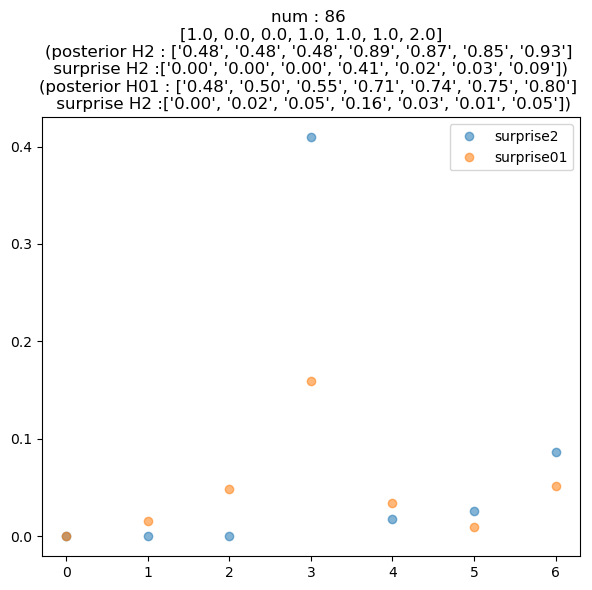

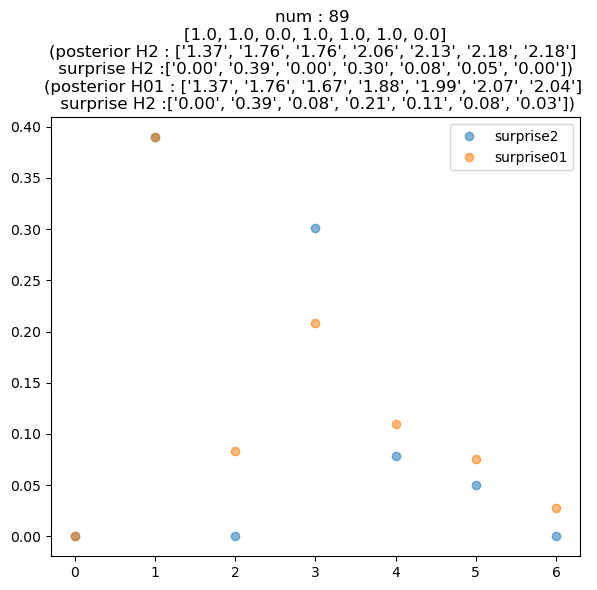

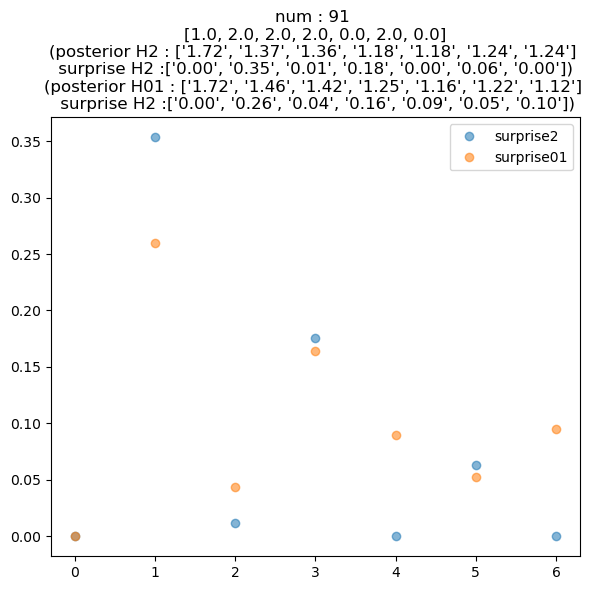

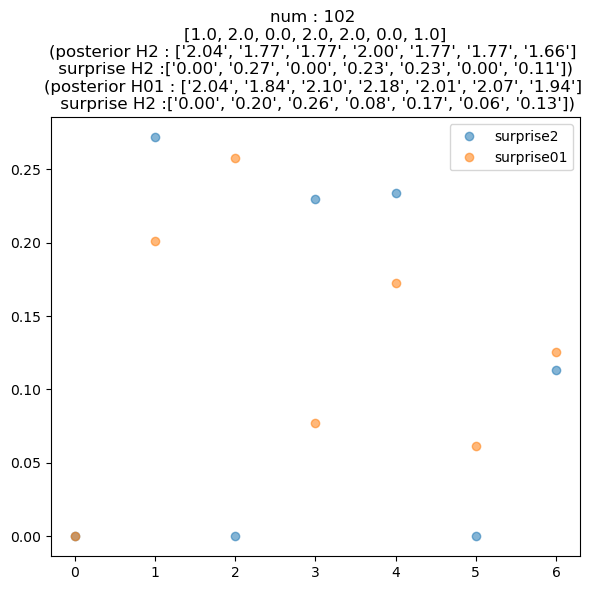

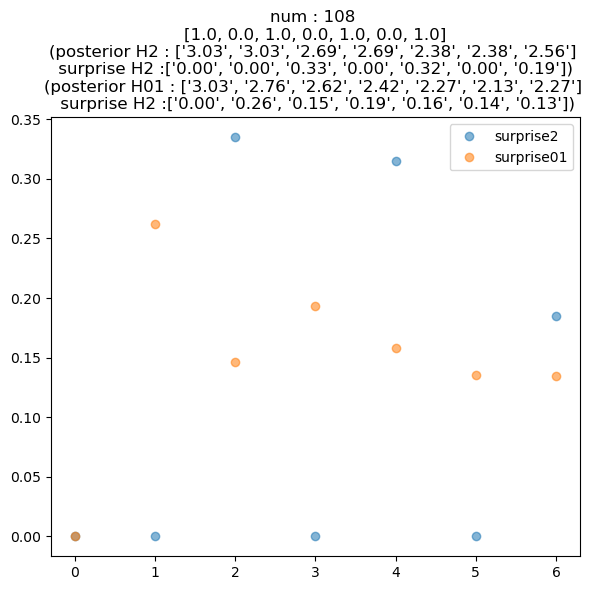

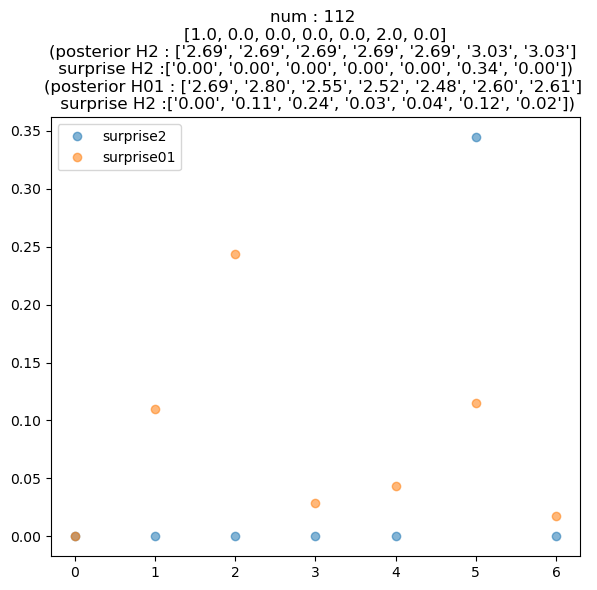

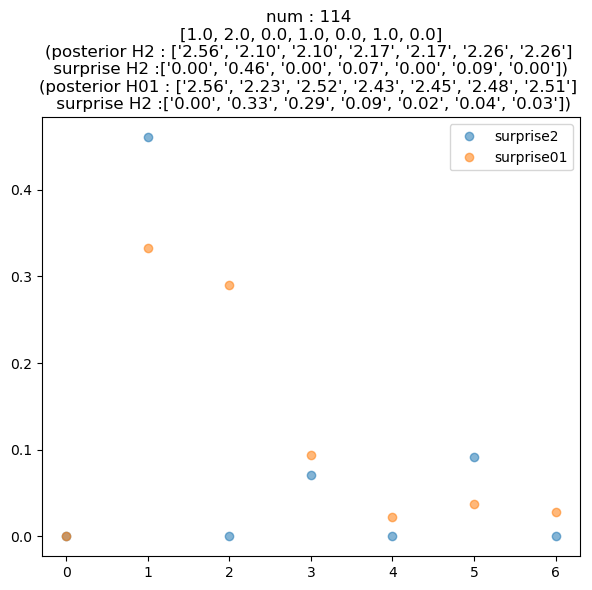

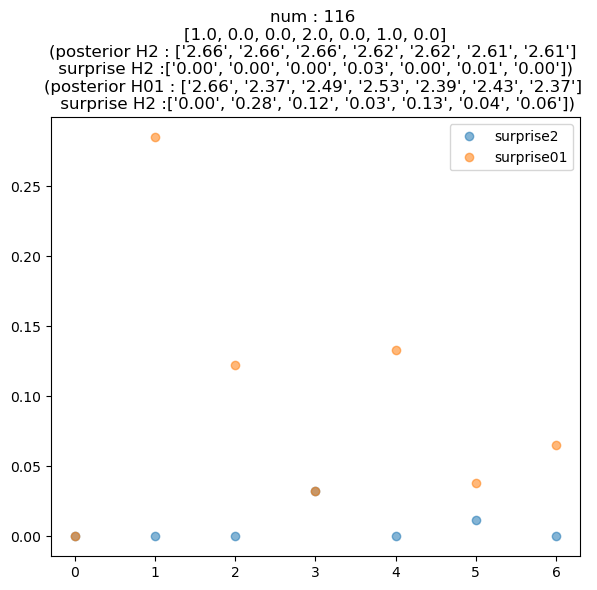

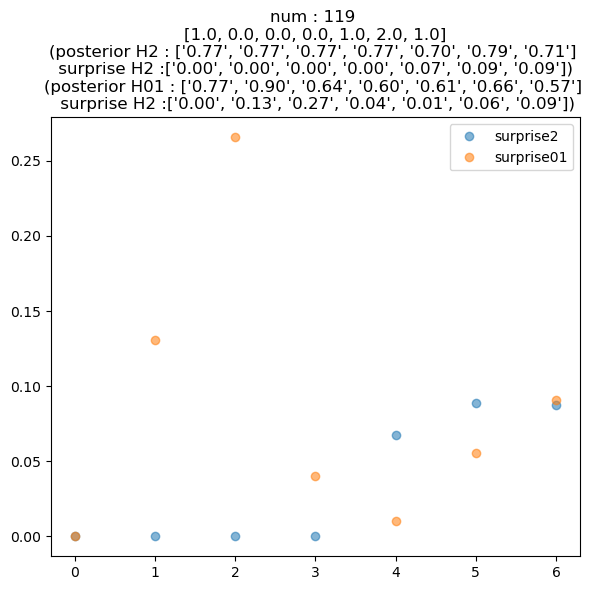

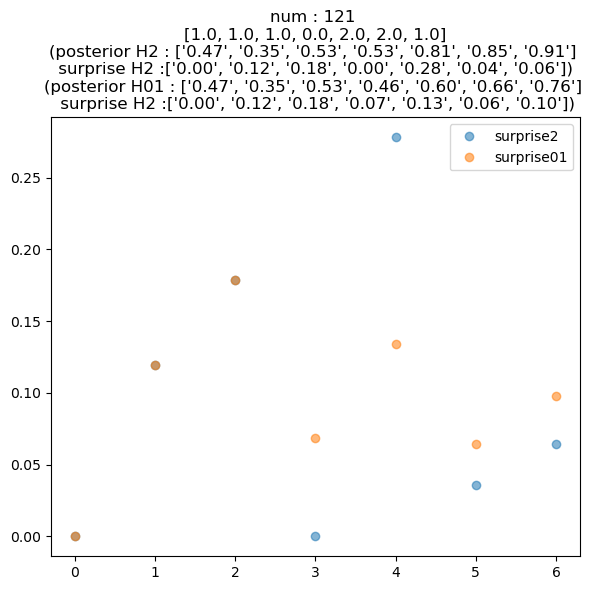

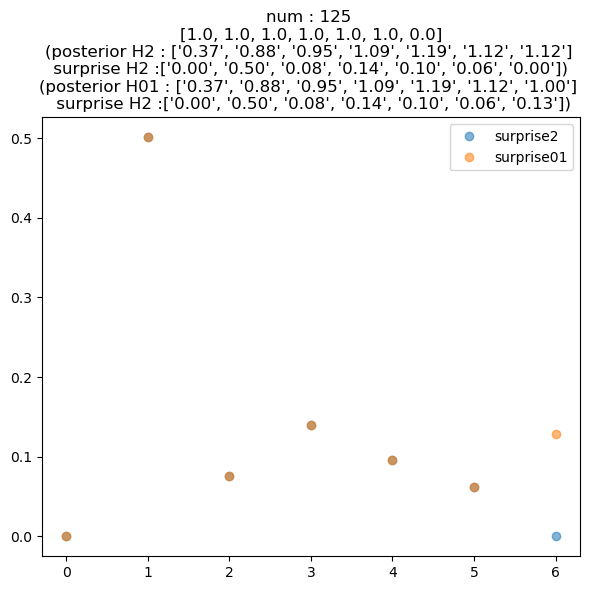

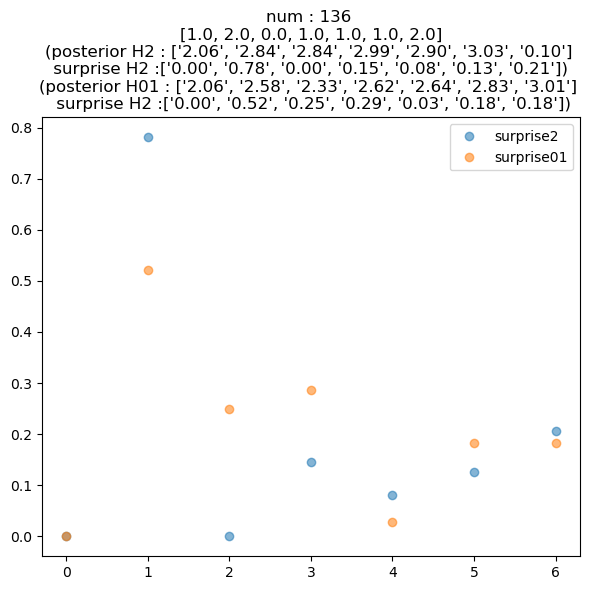

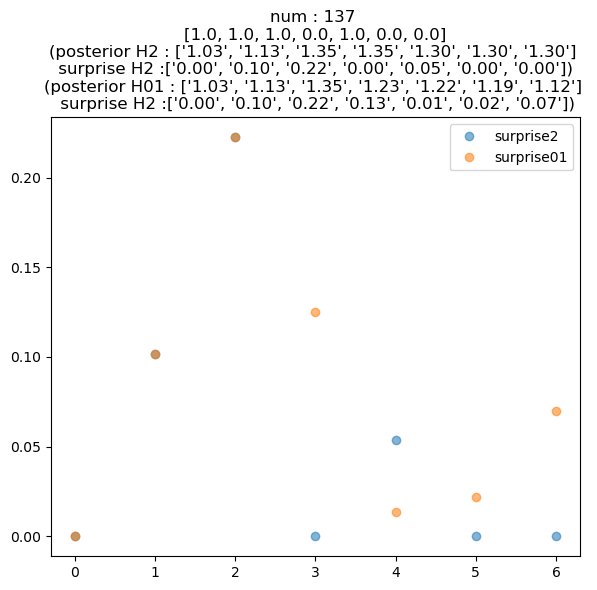

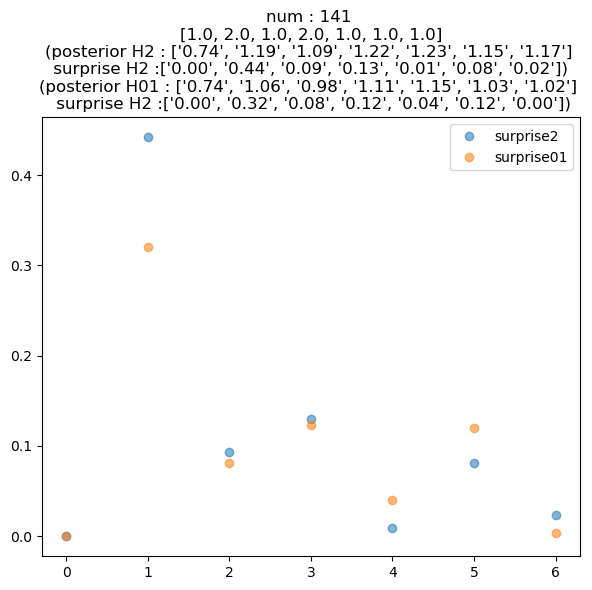

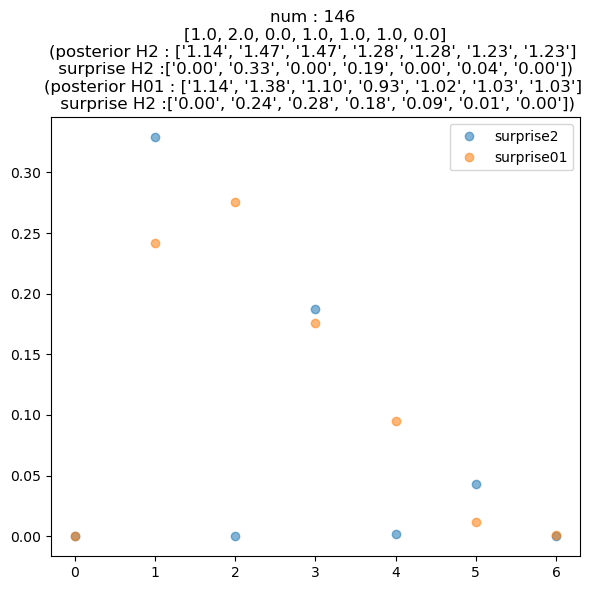

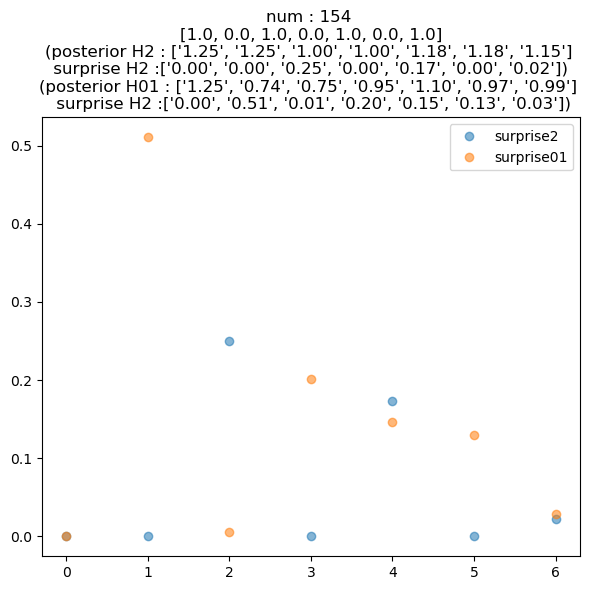

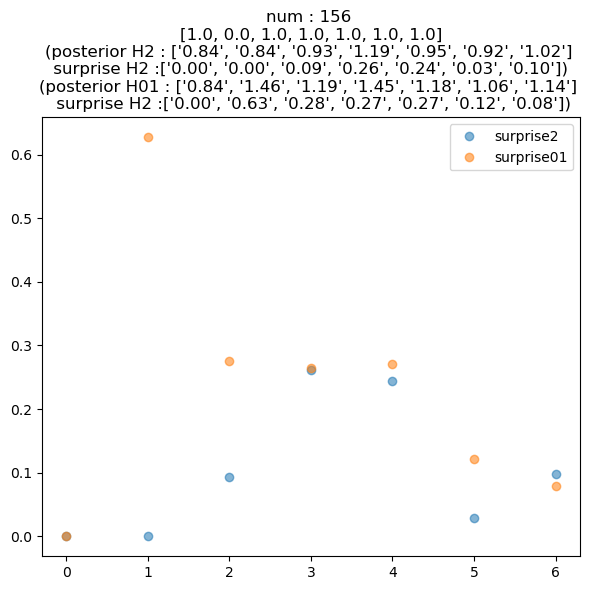

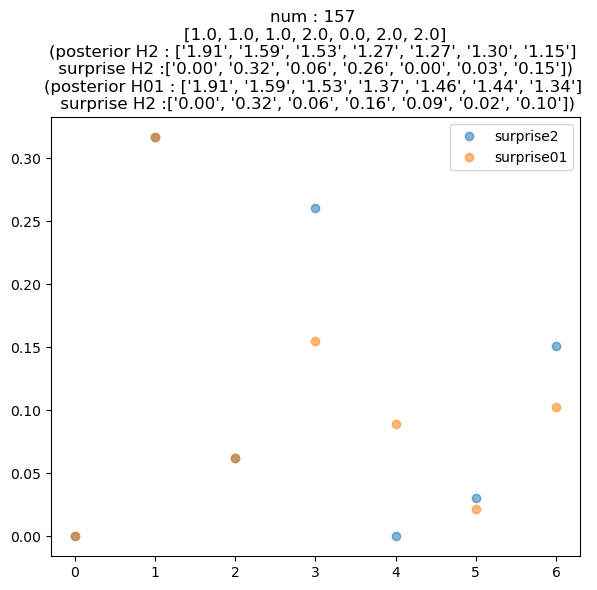

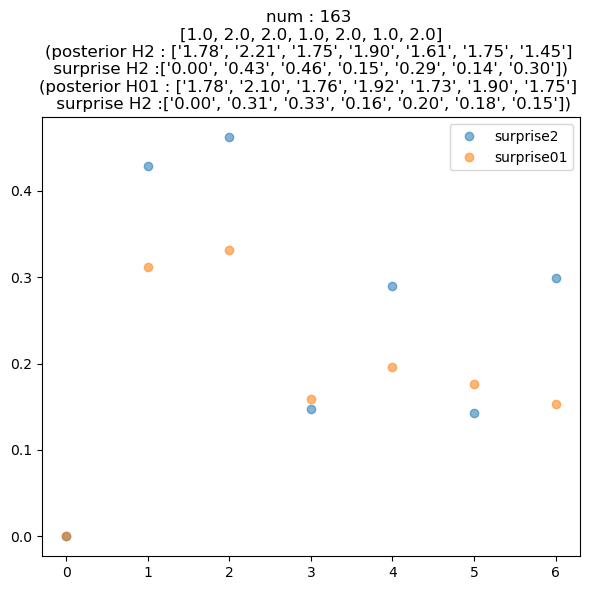

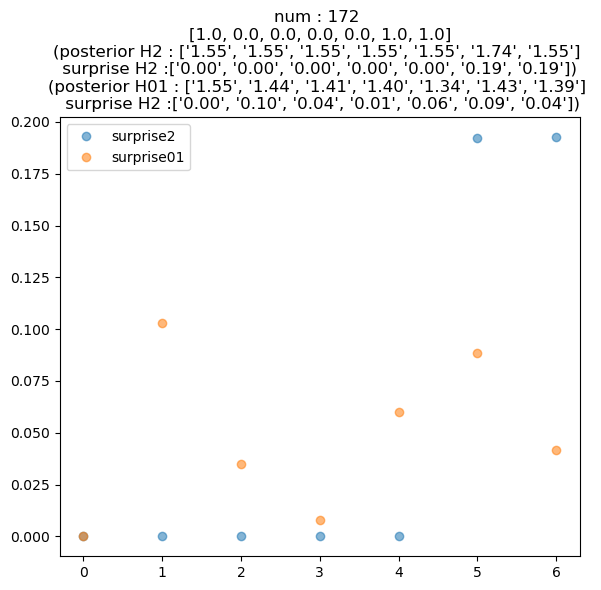

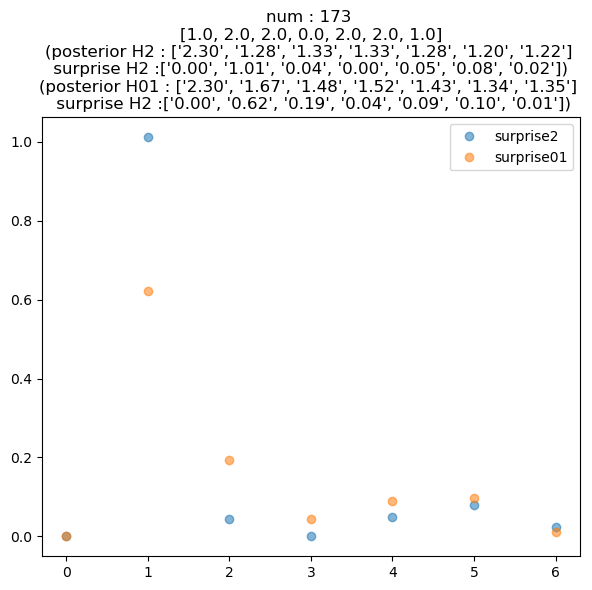

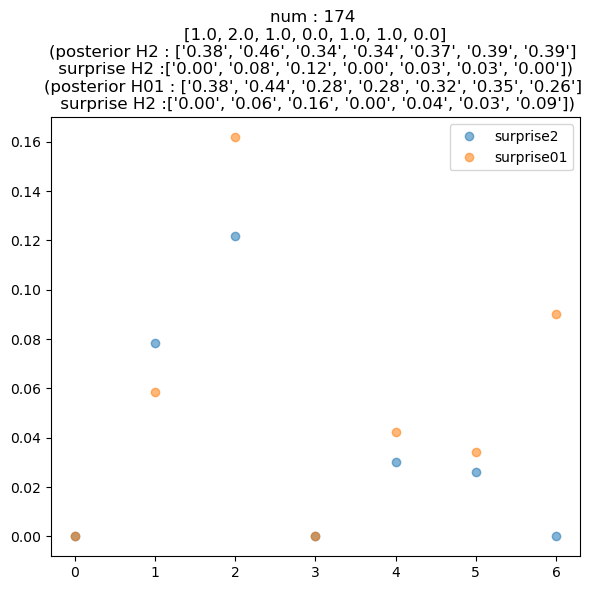

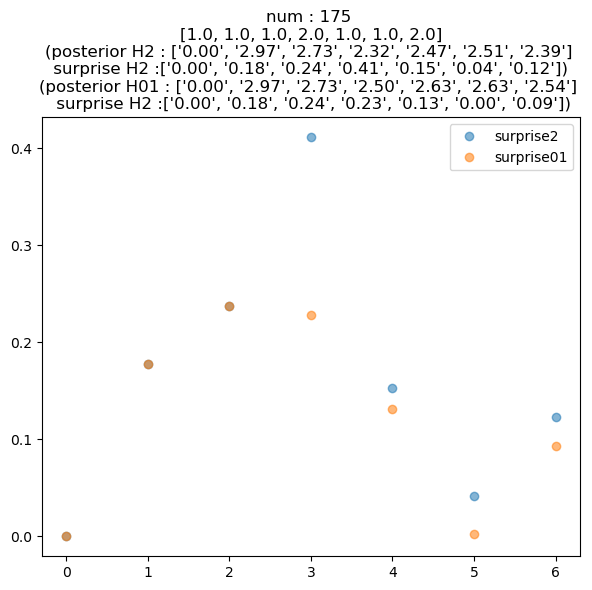

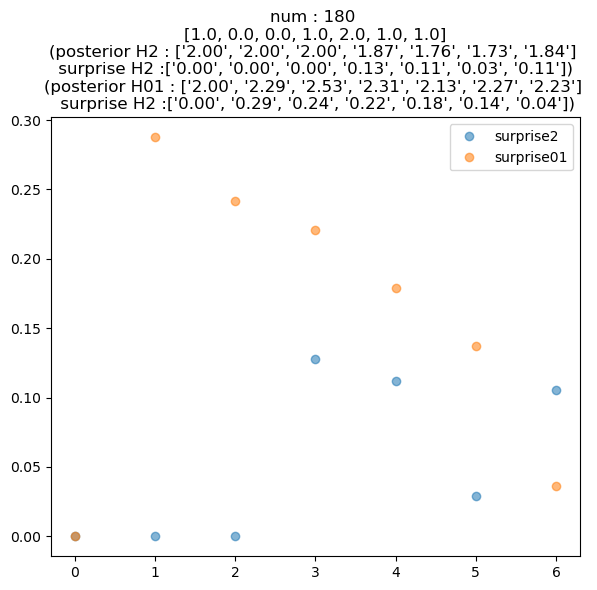

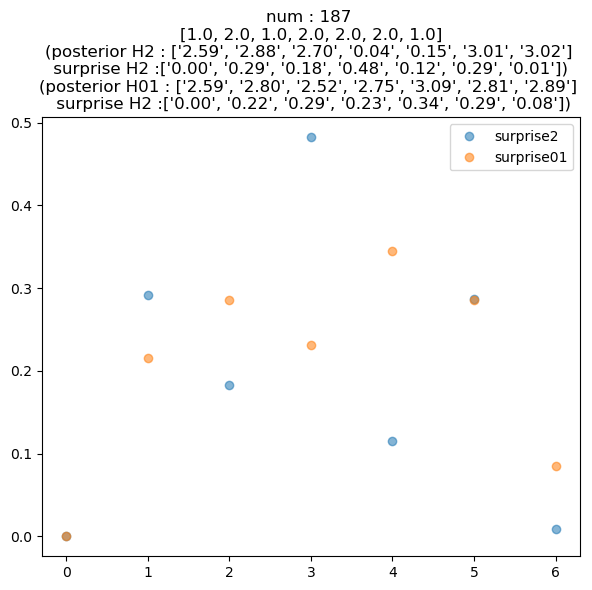

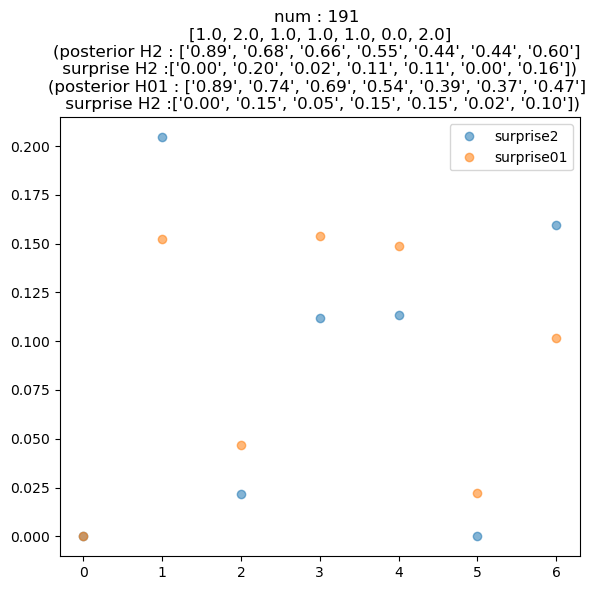

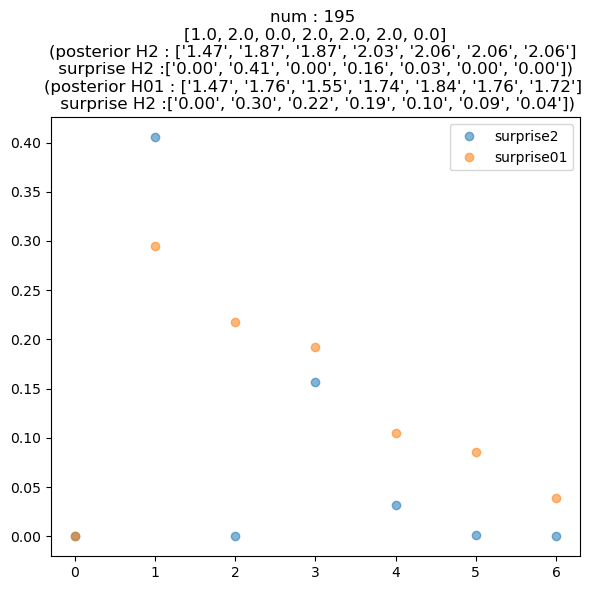

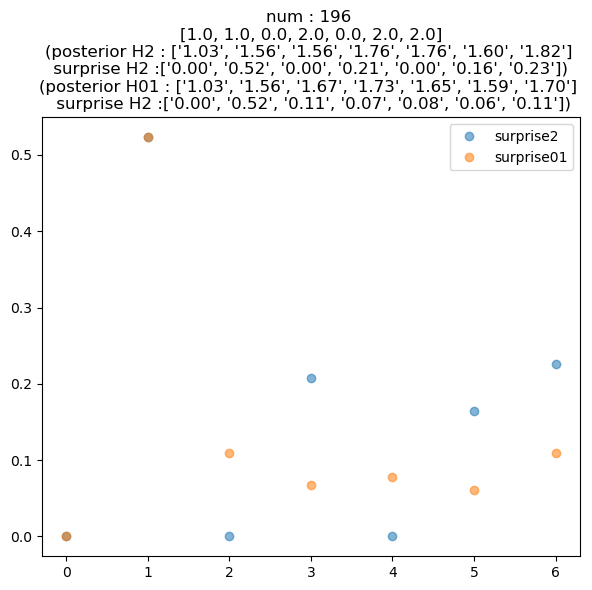

In [70]:
# for the SUBoptimal model
for num in range(198) :
    list_presented_angles = df_radian_W["presented_angles"].iloc[num] 
    list_perceived_colors = df_radian_W["stimulus_weights"].iloc[num]

    target2, length2, posteriors2, surprise2 = optimal_model_poster_WH2(list_presented_angles,list_perceived_colors)
    target01, length01, posteriors01, surprise01 = optimal_model_poster_WH01(list_presented_angles,list_perceived_colors)

   
    if length2 > 6 : 
        # print("posterior", posteriors)
        # print("surprise", surprise)
        # print("presented angles",
        # list_presented_angles)
        # print("colors", list_perceived_colors)
        ### plot sur cercle 
        rounded_post2 = [f"{x:.2f}" for x in posteriors2]
        rounded_surprise2 = [f"{x:.2f}" for x in surprise2]
        
        rounded_post01 = [f"{x:.2f}" for x in posteriors01]
        rounded_surprise01 = [f"{x:.2f}" for x in surprise01]
        
        
        plt.figure(figsize=(6,6))
        plt.plot(surprise2, 'o', alpha=0.55, label="surprise2")
        plt.plot(surprise01, 'o', alpha=0.55, label="surprise01")

        # ax.scatter(posteriors, np.ones_like(posteriors),
        #    alpha=0.55, label="rotated")
        # ax.scatter(surprise, np.ones_like(surprise),
        #         alpha=0.55, label="surprise")
        # ax.scatter(list_presented_angles, np.ones_like(list_presented_angles),
        #         alpha=0.55, label="presented angles")

        # ax.set_yticklabels([])   # enlève les labels du rayon
        plt.title(f"num : {num} \n{list_perceived_colors}\n(posterior H2 : {rounded_post2} \n surprise H2 :{rounded_surprise2}) \n(posterior H01 : {rounded_post01} \n surprise H2 :{rounded_surprise01})")
        plt.legend()
        plt.tight_layout()
        # ax.set_title(f"num : {num}")
        plt.show()

In [ ]:
def suboptimal_model (list_presented_angles, list_perceived_colors, rot1, rot2, w1, w2, sigma_r, sigma_integration, sigma_green, sigma_red, leak) : 
    """This model simulates the response of a participant. This is the suboptimal model, meaning that many parameters were given to simulate biases 
    and noise that can exist in the inference process.
    It returns only ONE target, or angle, for a given sequence 
    """
    
    
    # security that the lists have the same length
    if len(list_presented_angles) != len(list_perceived_colors) : 
        print(f"the list of presented angles (length = {len(list_presented_angles)}) and the list of colors presented (length = {len(list_perceived_colors)}) don't have the same length")
        return None
    
    # color mapping : each color viewed equals to an angle
    if type(list_perceived_colors[0]) == str : # if the list is a list of colors, and not of rotations in radian
        color_mapping_degrees = {"green" : np.deg2rad(rot1), "red" : np.deg2rad(rot2), "grey" : np.deg2rad(0)} # mapping of colors
        rotations_to_apply = [color_mapping_degrees[x] for x in list_perceived_colors] # rotations to apply 
    else : # if the list is not a list of colors
        rotations_to_apply = list_perceived_colors 

    corrected_angles = np.array(list_presented_angles) + np.array(rotations_to_apply) # the right angles, with the rotation applied

    weights_to_apply = [] 

    for color in list_perceived_colors :  # for each color, apply a weight. Because people could more or less ignore the rotations
        if color == "green" :
            weights_to_apply.append(w1)
        elif color == "red" : 
            weights_to_apply.append(w2)
        else : 
            weights_to_apply.append(1)
        
    rad_doubled = 2 * corrected_angles  # *2 
    if len(rad_doubled) == 0: 
        result = np.nan
    else:
        result = rad_doubled
    resulting_vector = 0
    for i, color in zip (range(len(result)), list_perceived_colors):
        if not  np.isnan(result[i]):
            # we add 3 sources of noise : 
            ## np.exp(-leak) : we uselually tend to forget all the 'prior', or everything before seen, and to rely more on the last stimulus
            ## normal distribution (sigma_integration) : the sigma is the variability : it's the source of noise that exists in the inference process, baseline for all colors because it's just the calculation cost
            ## normal distribution (sigma_green or sigma_red) : same thing, for the colors, it might be harder to compute the rotations
            if color == "green" : 
                resulting_vector = np.exp(-leak) * resulting_vector + (weights_to_apply[i] * cmath.exp(complex(0, result[i]+ np.random.normal(loc=0, scale=sigma_integration) + np.random.normal(loc=0, scale=sigma_green))))
            elif color == "red" :
                resulting_vector = np.exp(-leak) * resulting_vector + (weights_to_apply[i] * cmath.exp(complex(0, result[i]+ np.random.normal(loc=0, scale=sigma_integration) + np.random.normal(loc=0, scale=sigma_red)))) 
            else : 
                resulting_vector = np.exp(-leak) * resulting_vector + (weights_to_apply[i] * cmath.exp(complex(0, result[i]+ np.random.normal(loc=0, scale=sigma_integration))))             
    
    angle_res = np.angle(resulting_vector) / 2
    angle_variable = angle_res + np.random.normal(loc=0, scale=sigma_r)       # response noise : it is possible that people have the right answer but what they give is not exactly the right angle. It's the imprecision of response.   
    
    return angle_variable

# si leak = 0 → somme vectorielle classique
# si leak > 0 → effet de récence
# si w1 ≠ w2 → biais vert/rouge
# si sigma_green ≠ sigma_red → asymétrie computationnelle


In [ ]:
def targets_simulation_optimal (list_presented_angles, list_perceived_colors) : 
    """This model simulates the response of a participant. This is the optimal model.
    It returns ALL targets, or angles, for a given dataset of sequences and colors. 
    """
    targets = []
    for angle_sequence, colors in zip(list_presented_angles, list_perceived_colors) :
        x = optimal_model(angle_sequence, colors)
        targets.append(x)
    return targets 


def targets_simulation_suboptimal (list_presented_angles, list_perceived_colors, rot1, rot2, w1, w2, sigma_r, sigma_integration, sigma_green, sigma_red, leak) : 
    """This model simulates the response of a participant. This is the suboptimal model, meaning that many parameters were given to simulate biases 
    and noise that can exist in the inference process.
    It returns ALL targets, or angles, for a given dataset of sequences and colors. 
    """
    targets = []
    for angle_sequence, colors in zip(list_presented_angles, list_perceived_colors) :
        x = suboptimal_model(angle_sequence, colors, rot1, rot2, w1, w2, sigma_r, sigma_integration, sigma_green, sigma_red, leak)
        targets.append(x)
    return targets 

### tests

In [ ]:
# for the optimal model
list_presented_angles = df_radian["presented_angles"].iloc[0] 
list_perceived_colors = df_radian["stimulus_rotations"].iloc[0]

x = optimal_model(list_presented_angles,list_perceived_colors)

if round(x%np.pi,3) == round(df_radian["target"].iloc[0]%np.pi, 3) :
    print("TRUE")
    print(x%np.pi, df_radian["target"].iloc[0]%np.pi)
else : 
    print("FALSE", x%np.pi, df_radian["target"].iloc[0]%np.pi)
    


TRUE
2.16758177668523 2.16758177668523


In [ ]:
# for the SUBoptimal model
list_presented_angles = df_radian["presented_angles"].iloc[0] 
list_perceived_colors = df_radian["color_map_str"].iloc[0]

x = suboptimal_model(list_presented_angles,list_perceived_colors,
                    rot1 = 45,
                    rot2 = -45, 
                    w1 = 1, 
                    w2 = 1, 
                    sigma_r = np.deg2rad(0), 
                    sigma_integration = np.deg2rad(0), 
                    sigma_green = np.deg2rad(0), 
                    sigma_red = np.deg2rad(0), 
                    leak = 0
    )

x
if round(x%np.pi,3) == round(df_radian["target"].iloc[0], 3) :
    print("TRUE")
    print("x=",np.rad2deg(x%np.pi), ", target origine=",np.rad2deg((df_radian["target"].iloc[0])))
else : 
    print("FALSE", "x=",np.rad2deg(x%np.pi), ", target origine=",np.rad2deg(df_radian["target"].iloc[0]))
    


FALSE x= 124.19328755353219 , target origine= -55.80671244646781


## Simulation on one fake subject 

### Optimal simulation

In [ ]:
# optimal model variables
df_radian["prediction_optimal"] = targets_simulation_optimal(df_radian["presented_angles"], df_radian["stimulus_rotations"])
df_radian["errors_to_target_optimal"] = circular_error(df_radian["prediction_optimal"], df_radian["target"])

df_radian["expected_angles_wo_rot_optimal"] = df_radian["presented_angles"].apply(CircularMean)
df_radian["error_wo_rotation_optimal"] = circular_error(df_radian["prediction_optimal"], df_radian["expected_angles_wo_rot_optimal"])

#### Plot for error vs target (optimal model)

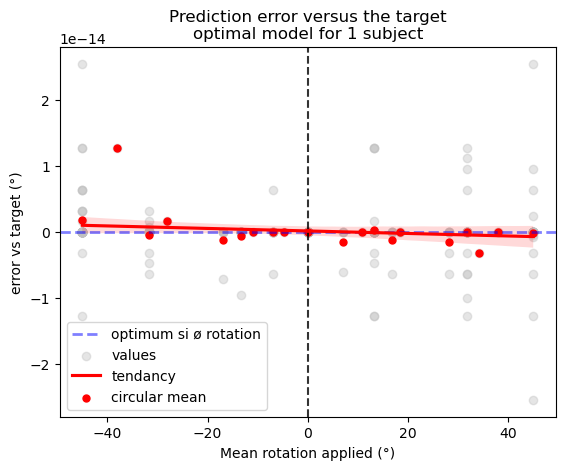

In [ ]:

x = (df_radian.groupby("mean_rotation_rounded")["errors_to_target_optimal"].apply(np.mean).reset_index().sort_values("mean_rotation_rounded"))
x = np.rad2deg(x)

plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="blue", linestyle="--", label= "optimum si ø rotation", alpha = 0.5, linewidth =2)   

sns.regplot(x=np.rad2deg(df_radian["mean_rotation_rounded"]), y=np.rad2deg(df_radian["errors_to_target_optimal"]), data=df_radian, color = "silver", label = "values", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "tendancy"})
plt.scatter(x["mean_rotation_rounded"], x["errors_to_target_optimal"], color="red", s=25, label="circular mean")

plt.xlabel("Mean rotation applied (°)")
plt.ylabel("error vs target (°)")
plt.title("Prediction error versus the target\noptimal model for 1 subject")
plt.legend()
plt.show()

#### Plot for error vs no rotations (optimal model)

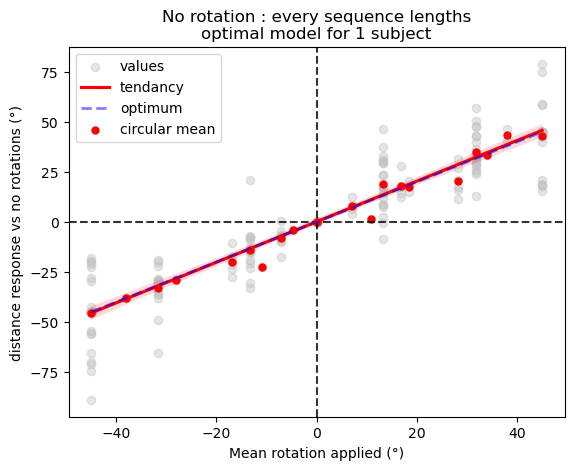

In [ ]:
x = (df_radian.groupby("mean_rotation_rounded")["error_wo_rotation_optimal"].apply(np.mean).reset_index().sort_values("mean_rotation_rounded"))
x = np.rad2deg(x)

plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   
sns.regplot(x=df_radian["mean_rotation_rounded"].apply(np.rad2deg), y=df_radian["error_wo_rotation_optimal"].apply(np.rad2deg), data=df_radian, color = "silver", label = "values", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "tendancy"})
borne = x["mean_rotation_rounded"]
plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
plt.scatter(x["mean_rotation_rounded"], x["error_wo_rotation_optimal"], color="red", s=25, label="circular mean")
plt.xlabel("Mean rotation applied (°)")
plt.ylabel("distance response vs no rotations (°)")
plt.title("No rotation : every sequence lengths\noptimal model for 1 subject")
plt.legend()
plt.show()

#### plot for error vs no rotations for each sequence length (optimal model)

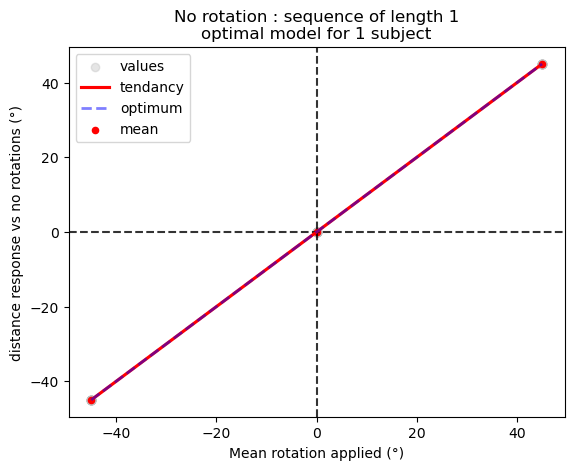

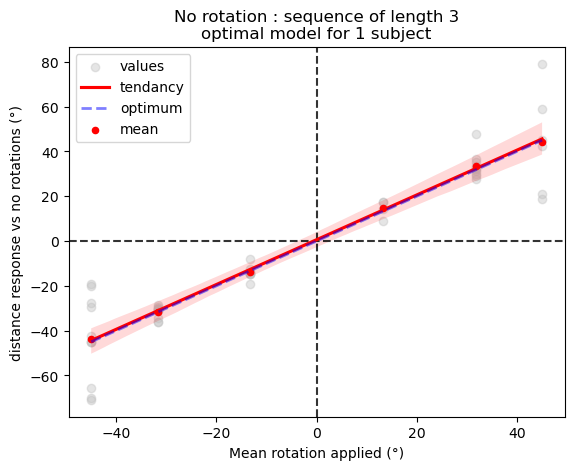

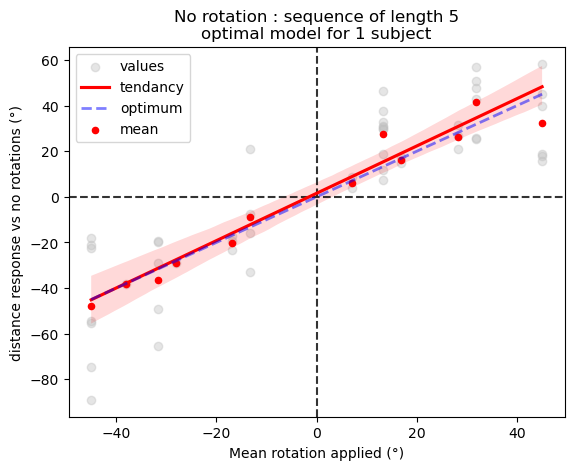

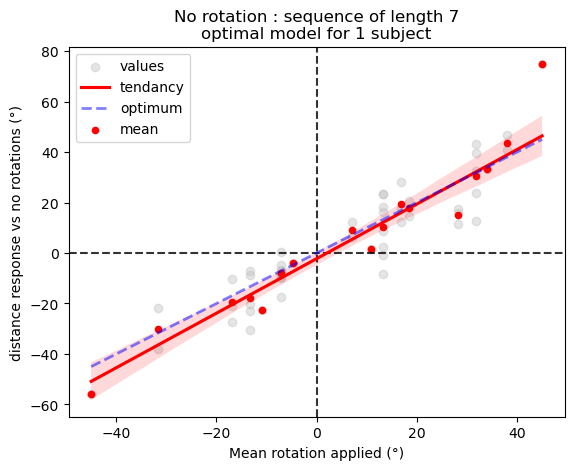

In [ ]:
for seqlen in [1,3,5,7] :
    plt.figure()
    x = (df_radian[df_radian["length of sequence"]==seqlen].groupby("mean_rotation_rounded")["error_wo_rotation_optimal"].apply(np.mean).reset_index().sort_values("mean_rotation_rounded"))
    x = np.rad2deg(x)

    plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
    plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   

    borne = x["mean_rotation_rounded"]
    sns.regplot(x=np.rad2deg(df_radian[df_radian["length of sequence"]==seqlen]["mean_rotation_rounded"]), y=np.rad2deg(df_radian[df_radian["length of sequence"]==seqlen]["error_wo_rotation_optimal"]), data=df_radian[df_radian["length of sequence"]==seqlen], color = "silver", label = "values", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "tendancy"})
    plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
    plt.scatter(x["mean_rotation_rounded"], x["error_wo_rotation_optimal"], color="red", s=20, label="mean")

    plt.xlabel("Mean rotation applied (°)")
    plt.ylabel("distance response vs no rotations (°)")
    plt.title(f"No rotation : sequence of length {seqlen}\noptimal model for 1 subject")
    plt.legend()
    plt.show()

### Suboptimal simulation

In [ ]:
# suboptimal model variables

df_radian["prediction_suboptimal"] = targets_simulation_suboptimal(df_radian["presented_angles"], df_radian["color_map_str"],
                                    rot1 = 45,
                                    rot2 = -45, 
                                    w1 = 1,
                                    w2 = 1,
                                    sigma_r = np.deg2rad(1),
                                    sigma_integration = np.deg2rad(1),
                                    sigma_green = np.deg2rad(1),
                                    sigma_red = np.deg2rad(1),
                                    leak = 0)
df_radian["errors_to_target_suboptimal"] = circular_error(df_radian["prediction_suboptimal"], df_radian["target"])
df_radian["expected_angles_wo_rot_suboptimal"] = df_radian["presented_angles"].apply(CircularMean)
df_radian["error_wo_rotation_suboptimal"] = circular_error(df_radian["prediction_suboptimal"], df_radian["expected_angles_wo_rot_suboptimal"])
df_radian["optimum"] = circular_error(df_radian["expected_angles_wo_rot_suboptimal"], df_radian["target"])

#### Plot for error vs target (suboptimal model)

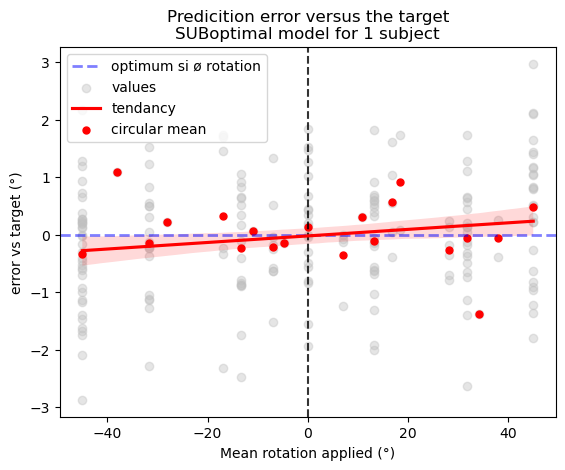

In [ ]:
x = (df_radian.groupby("mean_rotation_rounded")["errors_to_target_suboptimal"].apply(np.mean).reset_index().sort_values("mean_rotation_rounded"))
x = np.rad2deg(x)

plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="blue", linestyle="--", label= "optimum si ø rotation", alpha = 0.5, linewidth =2)   

sns.regplot(x=np.rad2deg(df_radian["mean_rotation_rounded"]), y=np.rad2deg(df_radian["errors_to_target_suboptimal"]), data=df_radian, color = "silver", label = "values", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "tendancy"})
plt.scatter(x["mean_rotation_rounded"], x["errors_to_target_suboptimal"], color="red", s=25, label="circular mean")

plt.xlabel("Mean rotation applied (°)")
plt.ylabel("error vs target (°)")
plt.title("Predicition error versus the target\nSUBoptimal model for 1 subject")
plt.legend()
plt.show()

#### Plot for error vs no rotations (suboptimal model)

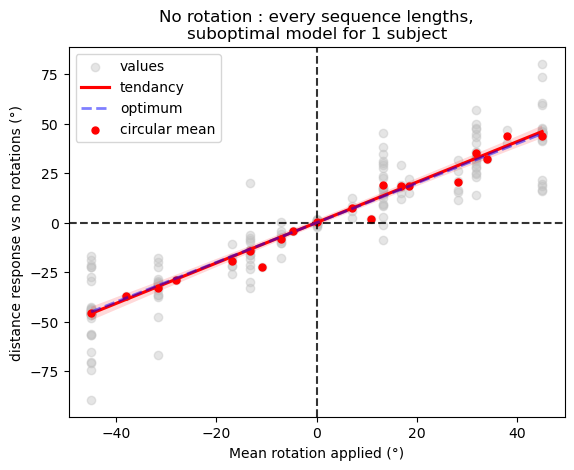

In [ ]:
x = (df_radian.groupby("mean_rotation_rounded")["error_wo_rotation_suboptimal"].apply(np.mean).reset_index().sort_values("mean_rotation_rounded"))
x = np.rad2deg(x)

plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   
sns.regplot(x=df_radian["mean_rotation_rounded"].apply(np.rad2deg), y=df_radian["error_wo_rotation_suboptimal"].apply(np.rad2deg), data=df_radian, color = "silver", label = "values", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "tendancy"})
borne = x["mean_rotation_rounded"]
plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
plt.scatter(x["mean_rotation_rounded"], x["error_wo_rotation_suboptimal"], color="red", s=25, label="circular mean")
plt.xlabel("Mean rotation applied (°)")
plt.ylabel("distance response vs no rotations (°)")
plt.title("No rotation : every sequence lengths,\nsuboptimal model for 1 subject")
plt.legend()
plt.show()

#### plot for error vs no rotations for each sequence length (suboptimal model)

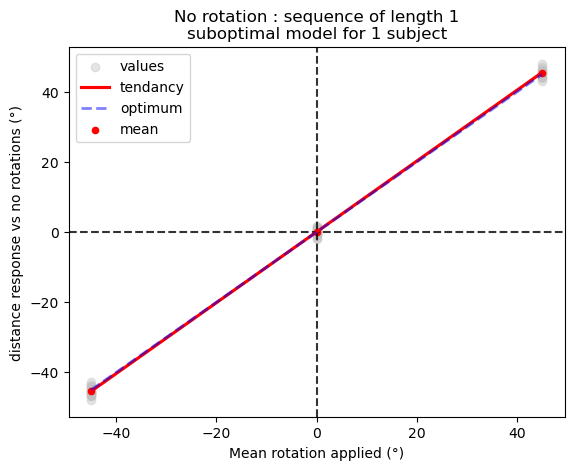

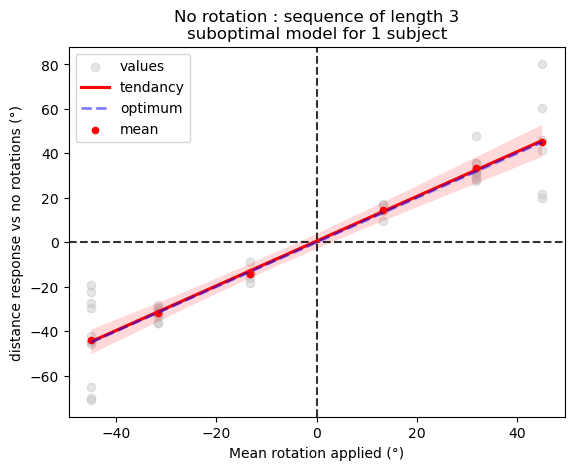

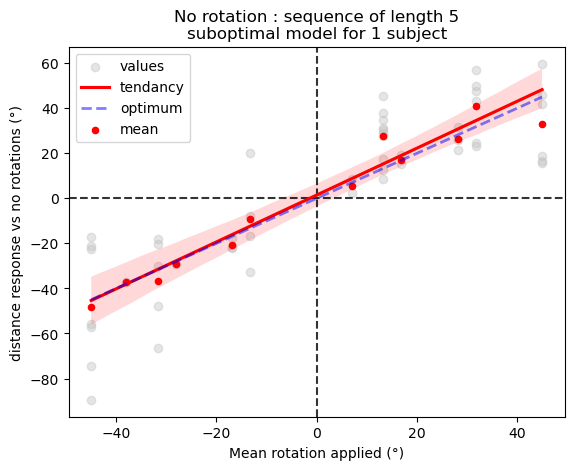

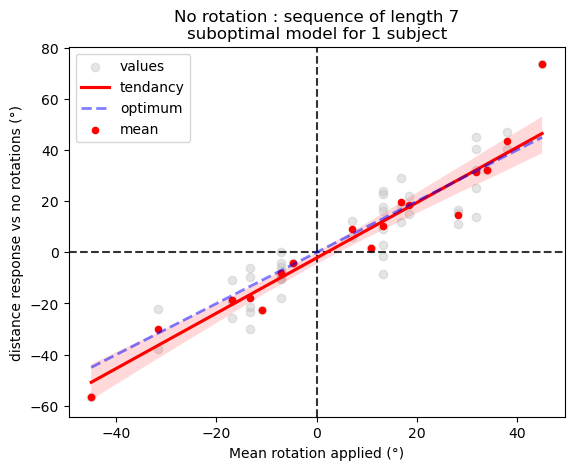

In [ ]:

for seqlen in [1,3,5,7] :
    plt.figure()
    x = (df_radian[df_radian["length of sequence"]==seqlen].groupby("mean_rotation_rounded")["error_wo_rotation_suboptimal"].apply(np.mean).reset_index().sort_values("mean_rotation_rounded"))
    x = np.rad2deg(x)

    plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
    plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   

    borne = x["mean_rotation_rounded"]
    sns.regplot(x=np.rad2deg(df_radian[df_radian["length of sequence"]==seqlen]["mean_rotation_rounded"]), y=np.rad2deg(df_radian[df_radian["length of sequence"]==seqlen]["error_wo_rotation_suboptimal"]), data=df_radian[df_radian["length of sequence"]==seqlen], color = "silver", label = "values", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "tendancy"})
    plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
    plt.scatter(x["mean_rotation_rounded"], x["error_wo_rotation_suboptimal"], color="red", s=20, label="mean")

    plt.xlabel("Mean rotation applied (°)")
    plt.ylabel("distance response vs no rotations (°)")
    plt.title(f"No rotation : sequence of length {seqlen}\nsuboptimal model for 1 subject")
    plt.legend()
    plt.show()

In [ ]:
df_radian["check"] = df_radian.apply(
    lambda row: optimal_model(row["presented_angles"],
                              row["color_map_str"]),
    axis=1
)

np.allclose(df_radian["check"], df_radian["prediction_optimal"])

# Si TRUE → ton modèle donne toujours le même résultat.

# La variabilité ne vient pas du modèle.
# Elle vient de la diversité des séquences.

True

## Simulation on all participants in behavioral task

In [ ]:
df_all["color_map_str"] = df_all["stimulus_rotations"].apply(lambda lst: [map_rotation_to_color(v) for v in lst])

# optimal simulation variables
df_all["prediction_optimal"] = targets_simulation_optimal(df_all["presented_angles"], df_all["stimulus_rotations"])
df_all["errors_to_target_optimal"] = circular_error(df_all["prediction_optimal"], df_all["target"])

df_all["expected_angles_wo_rot_optimal"] = df_all["presented_angles"].apply(CircularMean)
df_all["error_wo_rotation_optimal"] = circular_error(df_all["prediction_optimal"], df_all["expected_angles_wo_rot_optimal"])

# suboptimal simulation variables
df_all["prediction_suboptimal"] = targets_simulation_suboptimal(df_all["presented_angles"], df_all["color_map_str"],
                                    rot1 = 45,
                                    rot2 = -45, 
                                    w1 = 1,
                                    w2 = 1,
                                    sigma_r = np.deg2rad(0),
                                    sigma_integration = np.deg2rad(0),
                                    sigma_green = np.deg2rad(0),
                                    sigma_red = np.deg2rad(0),
                                    leak = 0)
df_all["errors_to_target_suboptimal"] = circular_error(df_all["prediction_suboptimal"], df_all["target"])
df_all["expected_angles_wo_rot_suboptimal"] = df_all["presented_angles"].apply(CircularMean)
df_all["error_wo_rotation_suboptimal"] = circular_error(df_all["prediction_suboptimal"], df_all["expected_angles_wo_rot_suboptimal"])
# df_all["optimum"] = circular_error(df_all["expected_angles_wo_rot"], df_all["target"])

(array([    0.,     0.,     0.,     0.,     0., 20676.,     0.,     0.,
            0.,     0.]),
 array([-0.5, -0.4, -0.3, -0.2, -0.1,  0. ,  0.1,  0.2,  0.3,  0.4,  0.5]),
 <BarContainer object of 10 artists>)

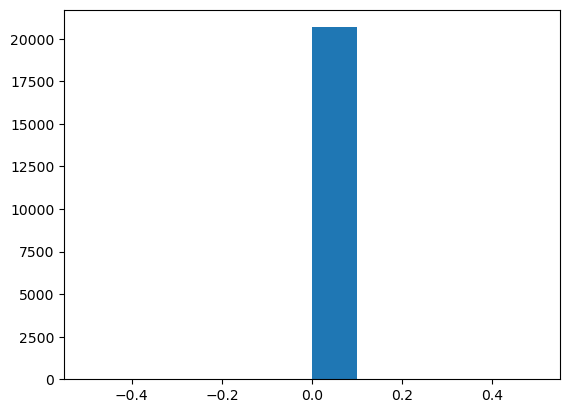

In [ ]:
plt.hist(np.rad2deg(df_all["errors_to_target_suboptimal"]))

In [ ]:
model_list=["suboptimal, optimal"]
model = "suboptimal"

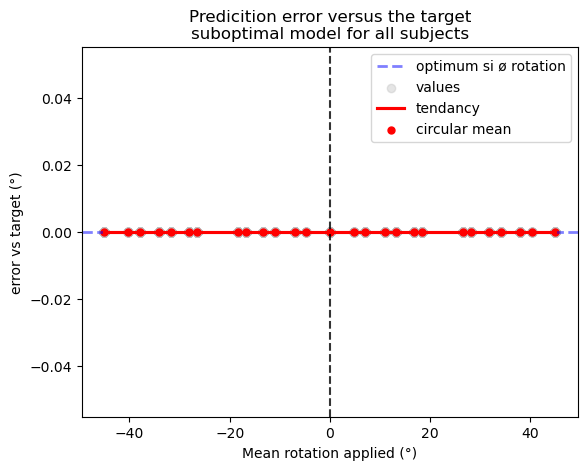

In [ ]:
x = (df_all.groupby("mean_rotation_rounded")[f"errors_to_target_{model}"].apply(np.mean).reset_index().sort_values("mean_rotation_rounded"))
x = np.rad2deg(x)

plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="blue", linestyle="--", label= "optimum si ø rotation", alpha = 0.5, linewidth =2)   

sns.regplot(x=np.rad2deg(df_all["mean_rotation_rounded"]), y=np.rad2deg(df_all[f"errors_to_target_{model}"]), data=df_all, color = "silver", label = "values", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "tendancy"})
plt.scatter(x["mean_rotation_rounded"], x[f"errors_to_target_{model}"], color="red", s=25, label="circular mean")

plt.xlabel("Mean rotation applied (°)")
plt.ylabel("error vs target (°)")
plt.title(f"Predicition error versus the target\n{model} model for all subjects")
plt.legend()
plt.show()

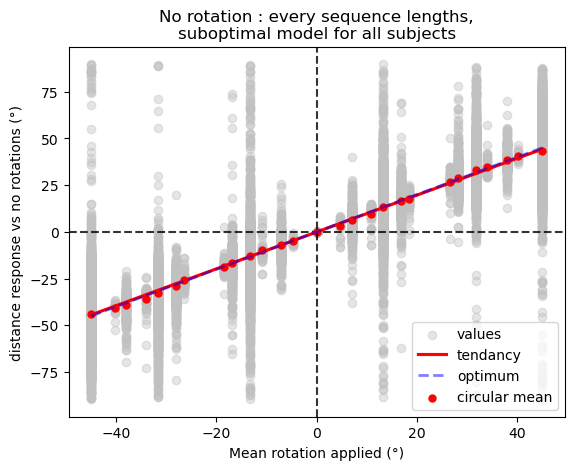

In [ ]:
x = (df_all.groupby("mean_rotation_rounded")[f"error_wo_rotation_{model}"].apply(np.mean).reset_index().sort_values("mean_rotation_rounded"))
x = np.rad2deg(x)

plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   
sns.regplot(x=df_all["mean_rotation_rounded"].apply(np.rad2deg), y=df_all[f"error_wo_rotation_{model}"].apply(np.rad2deg), data=df_all, color = "silver", label = "values", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "tendancy"})
borne = x["mean_rotation_rounded"]
plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
plt.scatter(x["mean_rotation_rounded"], x[f"error_wo_rotation_{model}"], color="red", s=25, label="circular mean")
plt.xlabel("Mean rotation applied (°)")
plt.ylabel("distance response vs no rotations (°)")
plt.title(f"No rotation : every sequence lengths,\n{model} model for all subjects")
plt.legend()
plt.show()

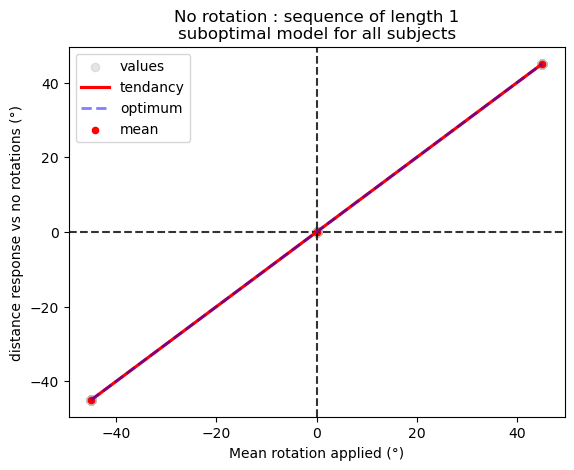

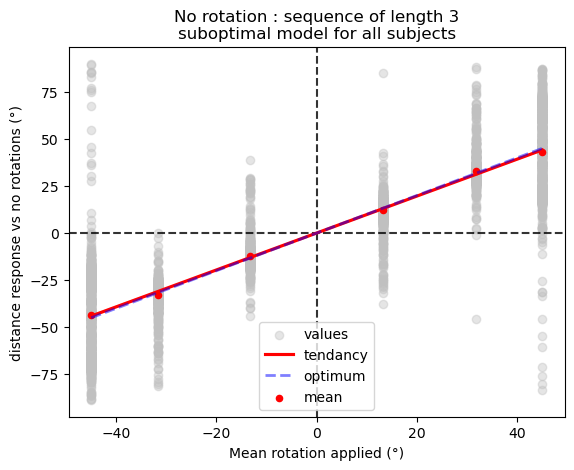

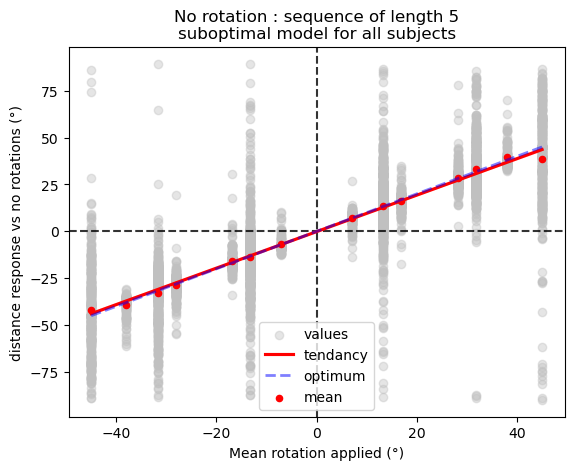

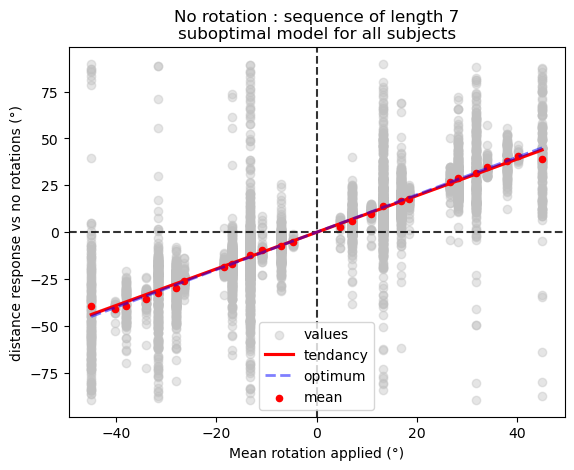

In [ ]:
for seqlen in [1,3,5,7] :
    plt.figure()
    x = (df_all[df_all["length of sequence"]==seqlen].groupby("mean_rotation_rounded")[f"error_wo_rotation_{model}"].apply(np.mean).reset_index().sort_values("mean_rotation_rounded"))
    x = np.rad2deg(x)

    plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
    plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   

    borne = x["mean_rotation_rounded"]
    sns.regplot(x=np.rad2deg(df_all[df_all["length of sequence"]==seqlen]["mean_rotation_rounded"]), y=np.rad2deg(df_all[df_all["length of sequence"]==seqlen][f"error_wo_rotation_{model}"]), data=df_all[df_all["length of sequence"]==seqlen], color = "silver", label = "values", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "tendancy"})
    plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
    plt.scatter(x["mean_rotation_rounded"], x[f"error_wo_rotation_{model}"], color="red", s=20, label="mean")

    plt.xlabel("Mean rotation applied (°)")
    plt.ylabel("distance response vs no rotations (°)")
    plt.title(f"No rotation : sequence of length {seqlen}\n{model} model for all subjects")
    plt.legend()
    plt.show()

### Example to see only one point through all

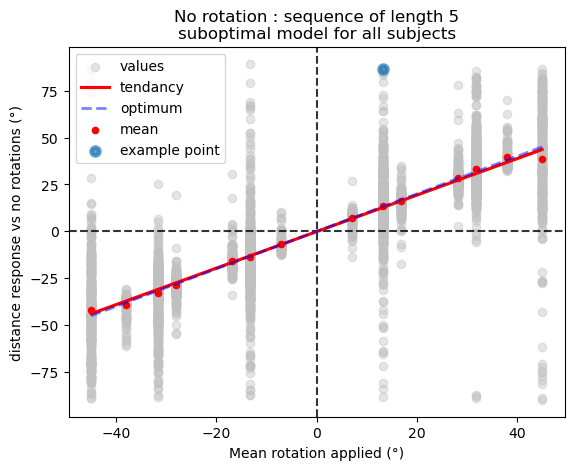

In [ ]:
plt.figure()
x = (df_all[df_all["length of sequence"]==5].groupby("mean_rotation_rounded")[f"error_wo_rotation_{model}"].apply(np.mean).reset_index().sort_values("mean_rotation_rounded"))
x = np.rad2deg(x)
plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   
borne = x["mean_rotation_rounded"]
sns.regplot(x=np.rad2deg(df_all[df_all["length of sequence"]==5]["mean_rotation_rounded"]), y=np.rad2deg(df_all[df_all["length of sequence"]==5][f"error_wo_rotation_{model}"]), data=df_all[df_all["length of sequence"]==5], color = "silver", label = "values", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "tendancy"})
plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
plt.scatter(x["mean_rotation_rounded"], x[f"error_wo_rotation_{model}"], color="red", s=20, label="mean")
plt.scatter(x=np.rad2deg(0.231824),y=np.rad2deg(1.513746), label = "example point", linewidths=3, alpha =0.7)
plt.xlabel("Mean rotation applied (°)")
plt.ylabel("distance response vs no rotations (°)")
plt.title(f"No rotation : sequence of length {5}\n{model} model for all subjects")
plt.legend()
plt.show()

In [ ]:
y=df_all[(df_all["length of sequence"]==5) & (df_all["mean_rotation_rounded"]==0.2318) & (df_all["error_wo_rotation_optimal"]==1.5137457046383422)]
y

,presented_angles,stimulus_rotations,expected_angles,target,mean_rotation,length of sequence,mean_rotation_rounded,color_map_str,prediction_optimal,errors_to_target_optimal,expected_angles_wo_rot_optimal,error_wo_rotation_optimal,prediction_suboptimal,errors_to_target_suboptimal,expected_angles_wo_rot_suboptimal,error_wo_rotation_suboptimal
15053,"[1.8468638164934772, 2.3831593424594693, -0.11...","[0.0, -0.7853981633974483, 0.7853981633974483,...","[1.8468638164934772, 1.597761179062021, 0.6673...",1.077701,0.231824,5,0.2318,"[grey, red, green, grey, green]",1.077701,0.0,-0.436045,1.513746,1.077701,0.0,-0.436045,1.513746


In [ ]:
presangles = np.array(y["presented_angles"])[0]
presangles

array([ 1.84686382,  2.38315934, -0.11800668,  0.89671091, -0.15204076])

In [ ]:
presangles_mean = CircularMean(presangles)
presangles_mean

-0.4360449827605044

In [ ]:
stimulus_rotation = np.array(y["stimulus_rotations"])[0]
stimulus_rotation

array([ 0.        , -0.78539816,  0.78539816,  0.        ,  0.78539816])

In [ ]:
# seen_angle_mean = CircularMean(presangles)
# seen_angle_mean

In [ ]:
expangles = presangles + stimulus_rotation
expangles

array([1.84686382, 1.59776118, 0.66739148, 0.89671091, 0.6333574 ])

In [ ]:
target1 = df_all["stimulus_rotations"] + df_all["presented_angles"]
target1.apply(CircularMean)

0       -0.357304
1       -0.131179
2       -0.478411
3        1.192362
4       -0.690294
           ...   
20671   -0.622761
20672   -0.245224
20673   -0.284909
20674   -0.144473
20675    0.587154
Length: 20676, dtype: float64

In [ ]:
target2 = df_all["stimulus_rotations"].apply(CircularMean) + df_all["presented_angles"].apply(CircularMean)
target2

0       -0.357304
1       -0.505238
2       -0.434831
3        1.113267
4       -0.690294
           ...   
20671   -0.622761
20672   -0.391759
20673   -0.306538
20674   -0.144473
20675    0.587154
Length: 20676, dtype: float64

In [ ]:
presangles_mean = df_all["presented_angles"].apply(CircularMean)

In [ ]:
import numpy as np
from scipy.optimize import minimize

# ---------------------------
# circular utils
# ---------------------------

def circ_angle(z):
    return np.angle(z) / 2

def circ_complex(theta):
    return np.exp(1j * 2 * theta)

def circular_error(a,b):
    return 0.5*np.angle(np.exp(1j*2*(a-b)))

# ---------------------------
# MODEL SIMULATION
# ---------------------------

def simulate_model(xang, xcue, params, nsmp=200):

    s_sen, g_sen, s_rot, d_rot_p, d_rot_m, s_fac, w_fac_p, w_fac_m, s_int, l_int, s_rep, p_lap = params

    nseq, nang = xang.shape

    z = np.zeros((nseq,nsmp), dtype=complex)

    for i in range(nang):

        valid = ~np.isnan(xang[:,i])
        angles = xang[valid,i]

        if i > 0:
            z[valid] *= 2**(-l_int)

        cues = xcue[valid,i]

        rot = np.zeros_like(angles)

        rot[cues==1] = d_rot_p
        rot[cues==-1] = d_rot_m

        weight = np.ones_like(angles)

        if i > 0:
            weight[cues==1] = w_fac_p
            weight[cues==-1] = w_fac_m

        noise = np.random.normal(0, np.sqrt(s_sen**2+s_rot**2), (len(angles),nsmp))

        ang = angles[:,None] + rot[:,None] + noise

        z[valid] += weight[:,None] * circ_complex(ang)

        if i>0:
            z[valid] += s_int*(np.random.randn(len(angles),nsmp)+1j*np.random.randn(len(angles),nsmp))

    y = circ_angle(z) + np.random.normal(0,s_rep,(nseq,nsmp))

    return y

# ---------------------------
# LIKELIHOOD
# ---------------------------

def log_likelihood(params, xang, xcue, yang):

    y = simulate_model(xang,xcue,params)

    err = circular_error(yang[:,None], y)

    sigma = params[10]

    ll = -0.5*(err/sigma)**2 - np.log(sigma)

    return np.sum(np.log(np.mean(np.exp(ll),axis=1)+1e-12))

# ---------------------------
# NEGATIVE LL FOR FITTING
# ---------------------------

def neg_ll(params, xang, xcue, yang):
    return -log_likelihood(params,xang,xcue,yang)

# ---------------------------
# FIT FUNCTION
# ---------------------------

def fit_model(xang, xcue, yang):

    init = np.array([
        0.1,  # s_sen
        0.0,  # g_sen
        0.1,  # s_rot
        0.7,  # d_rot_p
        -0.7, # d_rot_m
        0.5,  # s_fac
        1.0,  # w_fac_p
        1.0,  # w_fac_m
        0.5,  # s_int
        0.2,  # l_int
        0.2,  # s_rep
        0.05  # p_lap
    ])

    bounds = [
        (0,2),
        (-5,5),
        (0,2),
        (-np.pi/2,np.pi/2),
        (-np.pi/2,np.pi/2),
        (0,5),
        (0,5),
        (0,5),
        (0,5),
        (0,5),
        (1e-3,1),
        (0,0.3)
    ]

    result = minimize(
        neg_ll,
        init,
        args=(xang,xcue,yang),
        bounds=bounds,
        method="L-BFGS-B"
    )

    return result

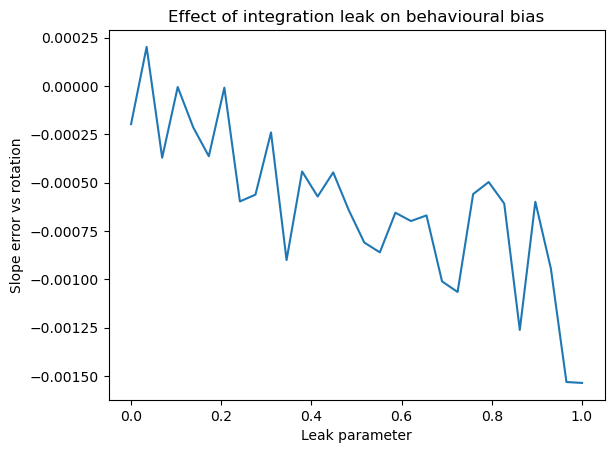

In [ ]:
from scipy.stats import linregress

leaks = np.linspace(0,1,30)
slopes = []

for leak in leaks:

    preds = targets_simulation_suboptimal(
        df_all["presented_angles"],
        df_all["color_map_str"],
        rot1=45,
        rot2=-45,
        w1=1,
        w2=1,
        sigma_r=np.deg2rad(1),
        sigma_integration=np.deg2rad(1),
        sigma_green=np.deg2rad(1),
        sigma_red=np.deg2rad(1),
        leak=leak
    )

    error = circular_error(preds, df_all["target"])

    slope, *_ = linregress(
        df_all["mean_rotation"],
        error
    )

    slopes.append(slope)
    
    
plt.plot(leaks, slopes)
plt.xlabel("Leak parameter")
plt.ylabel("Slope error vs rotation")
plt.title("Effect of integration leak on behavioural bias")
plt.show()

In [ ]:
leaks = np.linspace(0,1,20)
sigmas = np.linspace(0,10,20)

map_slope = np.zeros((20,20))

for i, leak in enumerate(leaks):
    for j, sigma in enumerate(sigmas):

        preds = targets_simulation_suboptimal(
            df_all["presented_angles"],
            df_all["color_map_str"],
            rot1=45,
            rot2=-45,
            w1=1,
            w2=1,
            sigma_r=np.deg2rad(1),
            sigma_integration=np.deg2rad(sigma),
            sigma_green=np.deg2rad(1),
            sigma_red=np.deg2rad(1),
            leak=leak
        )

        error = circular_error(preds, df_all["target"])

        slope, *_ = linregress(
            df_all["mean_rotation"],
            error
        )

        map_slope[i,j] = slope
        
plt.imshow(map_slope, origin="lower",
           extent=[sigmas.min(), sigmas.max(),
                   leaks.min(), leaks.max()],
           aspect="auto")

plt.xlabel("Integration noise")
plt.ylabel("Leak")
plt.colorbar(label="Slope error vs rotation")
plt.title("Behavioural map of the model")
plt.show()

KeyboardInterrupt: 